# Dead Neuron Detection → Synaptic-Stripping Recovery → Importance Testing → Gradual Conservative Pruning
**CIFAR-100 · PyTorch · Google Colab (free T4)**

## Research methodology (short)
| Stage | What is done | Data used |
|---|---|---|
| 1. Baseline | Train a small ReLU CNN (no BatchNorm, so ReLU units are unambiguous) | train split, model selection on **validation** |
| 2. Detection | A neuron is **strictly dead** iff its post-ReLU output is *exactly 0* for every sample **and every spatial position** of a fixed 5 000-image calibration set. Identity = `(layer, index)` | calibration set (a fixed subset of the train split) |
| 3. Recovery | **Synaptic Stripping** on dead neurons only: zero the incoming weights that contribute most negatively to the pre-activation until the neuron fires. Labelled fallback: re-initialise incoming weights. Fine-tune, then *re-measure* which originally-dead neurons are alive (**revived**) and which are **still dead** | train / calibration / validation |
| 4. Importance testing | **(a) every remaining dead neuron** is temporarily disabled and the validation accuracy / loss is measured; **(b) every revived neuron** is also ablated, using *repeated* validation (5 disjoint folds + calibration loss). Weights are never touched | validation |
| 5. Gradual pruning | Revived neurons are **kept by default**. Only (i) remaining-dead neurons whose removal causes **no degradation** and (ii) revived neurons **proven to contribute nothing** are pruned – in **small batches**, each batch jointly re-verified, structurally removed, and (if needed) briefly fine-tuned. A batch that would push accuracy under the floor is **rolled back** | validation |
| 6. Final | Fine-tune the pruned model (accepted only if validation accuracy does not drop); evaluate **baseline, recovered and pruned once each** on the held-out **test** set (only at the very end) | test (sealed until Cell 14) |

> **Every dead neuron reaches a final decision** (*pruned* or *kept*, with a recorded reason). The test set is never used for any decision. To keep it sealed, the baseline's test accuracy is computed at the same final moment as the other two models (the baseline is frozen by then), rather than in the baseline-training step.

In [ ]:
# ===================== CELL 1 : SETUP, CONFIG, REPRODUCIBILITY =====================
import os, sys, time, json, copy, math, random, shutil, hashlib, warnings
from types import SimpleNamespace
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=UserWarning)

cfg = SimpleNamespace(
    seed=42,
    data_root="/content/data",
    ckpt_dir="/content/checkpoints",
    # ---- data ----
    n_val_per_class=50,        # 50 x 100 = 5 000 validation images (stratified), rest of the 50k train = 45 000
    calib_size=5000,           # fixed calibration set used for dead-neuron detection (subset of TRAIN split)
    batch_size=256,
    eval_batch_size=1000,
    # ---- model ----
    widths=(64, 128, 256, 512),    # hidden units: conv1, conv2, conv3 channels, fc1 units
    dropout=0.3,
    # ---- baseline training ----
    baseline_epochs=25,
    baseline_lr=1e-3,
    weight_decay=0.0,
    # ---- recovery (Synaptic Stripping) ----
    strip_fractions=[0.05, 0.10, 0.20, 0.30, 0.40, 0.50],  # max fraction of incoming weights stripped per neuron
    use_fallback=True,                  # labelled fallback: re-init incoming weights if stripping fails
    recovery_ft_epochs=8,
    recovery_ft_lr=3e-4,
    run_control=True,                   # control: baseline fine-tuned WITHOUT stripping (same epochs)
    # ---- importance / pruning ----
    prune_tol_pp=0.1,                   # max cumulative validation-accuracy drop (percentage points)
    prune_ft_epochs=10,
    prune_ft_lr=3e-4,
    # ---- misc ----
    resume=True,                        # reuse baseline checkpoint if config unchanged
    synthetic_smoke_test=False,         # True = random data, only for a quick pipeline dry-run (NOT real results)
)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(cfg.seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs(cfg.data_root, exist_ok=True)
os.makedirs(cfg.ckpt_dir, exist_ok=True)

results = {"test": {}}      # global store for all computed numbers (nothing is hard-coded)

print("PyTorch", torch.__version__, "| device:", device,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU (enable GPU: Runtime > Change runtime type > T4)")
print("Note: GPU max-pool backward is not bit-wise deterministic, so reruns are reproducible up to tiny float noise.")

PyTorch 2.11.0+cu130 | device: cuda | Tesla T4
Note: GPU max-pool backward is not bit-wise deterministic, so reruns are reproducible up to tiny float noise.


## Step 1 – Data: CIFAR-100 with train / validation / test splits
* The official 50 000 training images are split **stratified** into 45 000 train + 5 000 validation (50 per class). The official 10 000 test images are untouched until Cell 13.
* Normalisation mean/std are computed from the **45 000 training images only** (no leakage).
* Download is wrapped in retries and removes a corrupt partial download before retrying.
* The whole dataset is kept as GPU tensors (≈0.8 GB) and augmented on the GPU (random crop with 4-px padding + horizontal flip) – this avoids slow Colab DataLoader workers.
* A **calibration set** (5 000 clean train images, fixed indices) defines "dead".

In [ ]:
# ===================== CELL 2 : DATA =====================
N_CLASSES = 100

def _load_raw_cifar100(root, retries=3):
    import torchvision
    last_err = None
    for attempt in range(1, retries + 1):
        try:
            tr = torchvision.datasets.CIFAR100(root=root, train=True, download=True)
            te = torchvision.datasets.CIFAR100(root=root, train=False, download=True)
            return ((tr.data, np.array(tr.targets, dtype=np.int64)),
                    (te.data, np.array(te.targets, dtype=np.int64)))
        except Exception as e:
            last_err = e
            print(f"[data] attempt {attempt}/{retries} failed: {e!r}")
            shutil.rmtree(os.path.join(root, "cifar-100-python"), ignore_errors=True)   # remove corrupt extract
            tgz = os.path.join(root, "cifar-100-python.tar.gz")
            if os.path.exists(tgz): os.remove(tgz)                                       # remove corrupt archive
            time.sleep(2 * attempt)
    raise RuntimeError("Could not download CIFAR-100. Check the Colab internet connection and rerun.") from last_err

def _make_synthetic(n_per_class_train, n_per_class_test, seed=0):
    rng = np.random.default_rng(seed)
    def mk(n_pc):
        y = np.repeat(np.arange(N_CLASSES), n_pc).astype(np.int64)
        x = rng.integers(0, 256, size=(len(y), 32, 32, 3), dtype=np.uint8)
        return x, y
    return mk(n_per_class_train), mk(n_per_class_test)

def stratified_split(y, n_val_per_class, seed):
    rng = np.random.default_rng(seed)
    tr_idx, va_idx = [], []
    for c in range(N_CLASSES):
        idx = np.where(y == c)[0]
        rng.shuffle(idx)
        assert len(idx) > n_val_per_class, "not enough samples per class for the requested validation size"
        va_idx.append(idx[:n_val_per_class]); tr_idx.append(idx[n_val_per_class:])
    return np.sort(np.concatenate(tr_idx)), np.sort(np.concatenate(va_idx))

if cfg.synthetic_smoke_test:
    print("!!! SYNTHETIC RANDOM DATA - pipeline dry-run only, numbers are meaningless !!!")
    (x_full, y_full), (x_te, y_te) = _make_synthetic(n_per_class_train=cfg.n_val_per_class + 20, n_per_class_test=10)
else:
    (x_full, y_full), (x_te, y_te) = _load_raw_cifar100(cfg.data_root)

tr_idx, va_idx = stratified_split(y_full, cfg.n_val_per_class, cfg.seed)
assert len(set(tr_idx) & set(va_idx)) == 0, "train/val overlap!"
assert len(tr_idx) + len(va_idx) == len(y_full)

# normalisation statistics from the TRAIN split only
x_tr_u8, y_tr = x_full[tr_idx], y_full[tr_idx]
x_va_u8, y_va = x_full[va_idx], y_full[va_idx]
_tr_f = x_tr_u8.astype(np.float32) / 255.0
MEAN = _tr_f.mean(axis=(0, 1, 2)); STD = _tr_f.std(axis=(0, 1, 2)); del _tr_f
print("train-split mean:", MEAN.round(4), "std:", STD.round(4))

def to_tensor(x_u8):
    x = torch.from_numpy(x_u8).permute(0, 3, 1, 2).float().div_(255.0)
    x = (x - torch.tensor(MEAN).view(1, 3, 1, 1)) / torch.tensor(STD).view(1, 3, 1, 1)
    return x.contiguous().to(device)

X_train, Y_train = to_tensor(x_tr_u8), torch.from_numpy(y_tr).to(device)
X_val,   Y_val   = to_tensor(x_va_u8), torch.from_numpy(y_va).to(device)
X_test,  Y_test  = to_tensor(x_te),    torch.from_numpy(y_te).to(device)   # SEALED: first used in Cell 13
del x_full, x_tr_u8, x_va_u8, x_te

# fixed calibration set: clean (un-augmented) subset of the TRAIN split
_rng = np.random.default_rng(cfg.seed + 1)
calib_idx = np.sort(_rng.choice(X_train.shape[0], size=min(cfg.calib_size, X_train.shape[0]), replace=False))
X_calib, Y_calib = X_train[calib_idx], Y_train[calib_idx]

print(f"train {tuple(X_train.shape)} | val {tuple(X_val.shape)} | test {tuple(X_test.shape)} | calib {tuple(X_calib.shape)}")
print("val images per class (min/max):", torch.bincount(Y_val, minlength=N_CLASSES).min().item(),
      torch.bincount(Y_val, minlength=N_CLASSES).max().item())

def augment_batch(x):
    """GPU augmentation: random flip + random 32x32 crop from a 4-px reflect-padded image."""
    B = x.shape[0]
    flip = torch.rand(B, device=x.device) < 0.5
    x = torch.where(flip.view(B, 1, 1, 1), x.flip(3), x)
    xp = F.pad(x, (4, 4, 4, 4), mode="reflect")
    i = torch.randint(0, 9, (B,), device=x.device); j = torch.randint(0, 9, (B,), device=x.device)
    ar = torch.arange(32, device=x.device)
    rows = (i.view(B, 1) + ar).view(B, 1, 32, 1)
    cols = (j.view(B, 1) + ar).view(B, 1, 1, 32)
    bidx = torch.arange(B, device=x.device).view(B, 1, 1, 1)
    cidx = torch.arange(3, device=x.device).view(1, 3, 1, 1)
    return xp[bidx, cidx, rows, cols]

def batches(X, Y, bs, shuffle=False, augment=False):
    n = X.shape[0]
    idx = torch.randperm(n, device=X.device) if shuffle else torch.arange(n, device=X.device)
    for s in range(0, n, bs):
        b = idx[s:s + bs]
        xb, yb = X[b], Y[b]
        yield (augment_batch(xb) if augment else xb), yb

_x, _ = next(batches(X_train, Y_train, 8, augment=True)); assert _x.shape == (8, 3, 32, 32)

100%|██████████| 169M/169M [52:33<00:00, 53.6kB/s]


train-split mean: [0.507  0.4866 0.4413] std: [0.2673 0.2564 0.2761]
train (45000, 3, 32, 32) | val (5000, 3, 32, 32) | test (10000, 3, 32, 32) | calib (5000, 3, 32, 32)
val images per class (min/max): 50 50


## Step 2 – Architecture choice
A small **VGG-style CNN without BatchNorm**, ≈2.5 M parameters:

`conv1(3→64)+ReLU → pool → conv2(64→128)+ReLU → pool → conv3(128→256)+ReLU → pool → flatten(256·4·4) → fc1(4096→512)+ReLU → dropout → fc2(512→100)`

* Each hidden layer has its **own `nn.ReLU` module** (no in-place, no reuse), so hooks see exactly one post-ReLU tensor per layer.
* **No BatchNorm**: BN re-centres pre-activations and makes "dead" ambiguous. Without it a neuron is dead iff its ReLU output is 0.
* A **neuron** = one output *channel* in conv layers (all its spatial positions) and one unit in `fc1`. Four prunable hidden layers: `conv1, conv2, conv3, fc1`.
* Pruning a conv channel removes the filter, its bias, the matching input channel of the next layer (for `conv3`: the matching 16 input features of `fc1`).
* Ablation is built into `forward` (an optional per-layer output mask), so it can be switched on/off with no weight changes.

In [ ]:
# ===================== CELL 3 : MODEL =====================
HIDDEN_LAYERS = ["conv1", "conv2", "conv3", "fc1"]
RELU_OF = {"conv1": "relu1", "conv2": "relu2", "conv3": "relu3", "fc1": "relu4"}
SPATIAL = 4 * 4          # feature-map size after three 2x2 pools of a 32x32 image

class Net(nn.Module):
    def __init__(self, widths=(64, 128, 256, 512), n_classes=N_CLASSES, dropout=0.3):
        super().__init__()
        c1, c2, c3, f1 = [int(w) for w in widths]
        self.widths, self.n_classes, self.dropout_p = (c1, c2, c3, f1), n_classes, dropout
        self.conv1 = nn.Conv2d(3,  c1, 3, padding=1); self.relu1 = nn.ReLU()
        self.conv2 = nn.Conv2d(c1, c2, 3, padding=1); self.relu2 = nn.ReLU()
        self.conv3 = nn.Conv2d(c2, c3, 3, padding=1); self.relu3 = nn.ReLU()
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(c3 * SPATIAL, f1);       self.relu4 = nn.ReLU()
        self.drop = nn.Dropout(dropout)
        self.fc2 = nn.Linear(f1, n_classes)
        self.ablate = {}      # {layer_name: 0/1 mask over that layer's neurons}; empty = intact model

    def _ab(self, x, name):
        m = self.ablate.get(name)
        if m is None: return x
        return x * m.view(1, -1, *([1] * (x.dim() - 2)))

    def forward(self, x):
        x = self.pool(self._ab(self.relu1(self.conv1(x)), "conv1"))
        x = self.pool(self._ab(self.relu2(self.conv2(x)), "conv2"))
        x = self.pool(self._ab(self.relu3(self.conv3(x)), "conv3"))
        x = torch.flatten(x, 1)
        x = self._ab(self.relu4(self.fc1(x)), "fc1")
        return self.fc2(self.drop(x))

def count_params(model):          return sum(p.numel() for p in model.parameters())
def count_nonzero_params(model):  return int(sum((p != 0).sum().item() for p in model.parameters()))
def analytic_params(w, n_classes=N_CLASSES):
    c1, c2, c3, f1 = w
    return (3*c1*9 + c1) + (c1*c2*9 + c2) + (c2*c3*9 + c3) + (c3*SPATIAL*f1 + f1) + (f1*n_classes + n_classes)

_m = Net(cfg.widths, N_CLASSES, cfg.dropout).to(device)
assert _m(torch.zeros(2, 3, 32, 32, device=device)).shape == (2, N_CLASSES)
assert count_params(_m) == analytic_params(cfg.widths)
print(f"Hidden layer widths {cfg.widths} | parameters: {count_params(_m):,}")
del _m

Hidden layer widths (64, 128, 256, 512) | parameters: 2,519,780


In [ ]:
# ===================== CELL 4 : EVALUATION + TRAINING UTILITIES =====================
@torch.no_grad()
def evaluate(model, X, Y, bs=None):
    """returns (mean CE loss, accuracy in %)  - deterministic (eval mode)."""
    model.eval(); bs = bs or cfg.eval_batch_size
    tot, correct, n = 0.0, 0, 0
    for xb, yb in batches(X, Y, bs):
        out = model(xb)
        tot += F.cross_entropy(out, yb, reduction="sum").item()
        correct += (out.argmax(1) == yb).sum().item(); n += yb.numel()
    return tot / n, 100.0 * correct / n

def apply_masks(model, masks):
    """keep 'stripped' incoming weights at exactly 0 (masks: {layer: tensor shaped like layer.weight})."""
    if not masks: return
    with torch.no_grad():
        for name, m in masks.items():
            getattr(model, name).weight.mul_(m)

def save_ckpt(path, model, extra=None):
    torch.save({"state": model.state_dict(), "widths": model.widths, "extra": extra or {}}, path)

def train_model(model, epochs, lr, tag, masks=None, wd=0.0, ckpt_path=None):
    """Adam + cosine LR. Best epoch is chosen on VALIDATION accuracy (ties -> lower loss) and restored at the end."""
    model.to(device)
    if epochs <= 0: return pd.DataFrame(), -1
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    n_batches = math.ceil(X_train.shape[0] / cfg.batch_size)
    best = dict(acc=-1.0, loss=float("inf"), epoch=-1, state=None); hist = []
    apply_masks(model, masks)
    bar = tqdm(range(1, epochs + 1), desc=f"[{tag}] epochs")
    for ep in bar:
        model.train(); run_loss, run_correct, seen = 0.0, 0, 0
        for xb, yb in tqdm(batches(X_train, Y_train, cfg.batch_size, shuffle=True, augment=True),
                           total=n_batches, leave=False, desc=f"epoch {ep}"):
            opt.zero_grad(set_to_none=True)
            out = model(xb); loss = F.cross_entropy(out, yb)
            if not torch.isfinite(loss): raise RuntimeError(f"[{tag}] non-finite loss at epoch {ep}; lower the learning rate.")
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step(); apply_masks(model, masks)
            run_loss += loss.item() * yb.numel(); run_correct += (out.argmax(1) == yb).sum().item(); seen += yb.numel()
        sched.step()
        vl, va = evaluate(model, X_val, Y_val)
        hist.append(dict(epoch=ep, train_loss=run_loss / seen, train_acc=100.0 * run_correct / seen, val_loss=vl, val_acc=va))
        if va > best["acc"] + 1e-9 or (abs(va - best["acc"]) <= 1e-9 and vl < best["loss"]):
            best.update(acc=va, loss=vl, epoch=ep, state=copy.deepcopy(model.state_dict()))
            if ckpt_path: save_ckpt(ckpt_path, model, {"epoch": ep, "val_acc": va})
        bar.set_postfix(tr_loss=f"{hist[-1]['train_loss']:.3f}", val_acc=f"{va:.2f}", best=f"{best['acc']:.2f}@{best['epoch']}")
    model.load_state_dict(best["state"]); apply_masks(model, masks)
    return pd.DataFrame(hist), best["epoch"]

def show(df):
    try:
        from IPython.display import display; display(df)
    except Exception:
        print(df.to_string())

In [ ]:
# ===================== CELL 5 : TRAIN BASELINE =====================
set_seed(cfg.seed)
_fp = hashlib.md5(json.dumps(vars(cfg), sort_keys=True, default=str).encode()).hexdigest()[:8]
BASE_CKPT = os.path.join(cfg.ckpt_dir, f"baseline_{_fp}.pt")
HIST_CSV  = os.path.join(cfg.ckpt_dir, f"baseline_hist_{_fp}.csv")

baseline = Net(cfg.widths, N_CLASSES, cfg.dropout).to(device)
baseline_hist, loaded = None, False
if cfg.resume and os.path.exists(BASE_CKPT) and os.path.exists(HIST_CSV):
    try:
        ck = torch.load(BASE_CKPT, map_location=device)
        assert tuple(ck["widths"]) == tuple(cfg.widths)
        baseline.load_state_dict(ck["state"]); baseline_hist = pd.read_csv(HIST_CSV); loaded = True
        print(f"Loaded baseline checkpoint {BASE_CKPT} (same config fingerprint {_fp}).")
    except Exception as e:
        print("Checkpoint unusable, retraining:", repr(e)); baseline = Net(cfg.widths, N_CLASSES, cfg.dropout).to(device)
if not loaded:
    t0 = time.time()
    baseline_hist, best_ep = train_model(baseline, cfg.baseline_epochs, cfg.baseline_lr, "baseline",
                                         wd=cfg.weight_decay, ckpt_path=BASE_CKPT)
    baseline_hist.to_csv(HIST_CSV, index=False)
    print(f"Baseline trained in {time.time()-t0:.0f}s; best validation epoch = {best_ep}")

base_val_loss, base_val_acc = evaluate(baseline, X_val, Y_val)
base_train_loss, base_train_acc = evaluate(baseline, X_train, Y_train)
results["baseline"] = dict(val_loss=base_val_loss, val_acc=base_val_acc, train_loss=base_train_loss, train_acc=base_train_acc,
                           params=count_params(baseline), nonzero_params=count_nonzero_params(baseline))
print(f"Baseline | val acc {base_val_acc:.2f}% loss {base_val_loss:.4f} | train(clean) acc {base_train_acc:.2f}% "
      f"| params {results['baseline']['params']:,}   (test metrics are computed once, in Cell 13)")

[baseline] epochs:   0%|          | 0/25 [00:00<?, ?it/s]

epoch 1:   0%|          | 0/176 [00:00<?, ?it/s]

epoch 2:   0%|          | 0/176 [00:00<?, ?it/s]

epoch 3:   0%|          | 0/176 [00:00<?, ?it/s]

epoch 4:   0%|          | 0/176 [00:00<?, ?it/s]

epoch 5:   0%|          | 0/176 [00:00<?, ?it/s]

... (17 outputs left out)

epoch 23:   0%|          | 0/176 [00:00<?, ?it/s]

epoch 24:   0%|          | 0/176 [00:00<?, ?it/s]

epoch 25:   0%|          | 0/176 [00:00<?, ?it/s]

Baseline trained in 102s; best validation epoch = 22
Baseline | val acc 52.86% loss 1.7587 | train(clean) acc 64.67% | params 2,519,780   (test metrics are computed once, in Cell 13)


## Step 3 – Strict dead-neuron detection (identity-tracked)
A forward hook on every hidden `ReLU` records, **per neuron**, the running **maximum** of the post-ReLU output over *all* batches and, for conv layers, *all* spatial positions (`amax` over batch + H + W). Because post-ReLU values are ≥ 0, `max == 0` ⇔ output is exactly zero everywhere ⇔ **strictly dead**. Identity is stored as `(layer, index)`, the original index, forever.

In [ ]:
# ===================== CELL 6 : DEAD NEURON DETECTION =====================
@torch.no_grad()
def collect_activity(model, X, bs=500):
    """Per-neuron max and active-fraction of post-ReLU outputs, aggregated over ALL batches and spatial positions."""
    was_training = model.training; model.eval()
    st = {l: dict(max=None, pos=None, total=0) for l in HIDDEN_LAYERS}
    handles = []
    def make_hook(l):
        def hook(mod, inp, out):
            a = out.detach()
            dims = tuple([0] + list(range(2, a.dim())))          # reduce batch (+ H, W for conv): keep channel dim
            mx, pos = a.amax(dim=dims), (a > 0).sum(dim=dims)
            s = st[l]
            s["max"] = mx if s["max"] is None else torch.maximum(s["max"], mx)
            s["pos"] = pos if s["pos"] is None else s["pos"] + pos
            s["total"] += a.numel() // a.shape[1]
        return hook
    for l in HIDDEN_LAYERS:
        handles.append(getattr(model, RELU_OF[l]).register_forward_hook(make_hook(l)))
    try:
        for xb, _ in batches(X, torch.zeros(X.shape[0], dtype=torch.long, device=X.device), bs):
            model(xb)
    finally:
        for h in handles: h.remove()
        model.train(was_training)
    out = {}
    for l in HIDDEN_LAYERS:
        assert torch.isfinite(st[l]["max"]).all(), f"non-finite activations in {l}"
        out[l] = dict(max=st[l]["max"].cpu(), active_frac=(st[l]["pos"].float() / st[l]["total"]).cpu())
    return out

def detect_dead(model, X):
    act = collect_activity(model, X)
    dead = {l: torch.nonzero(act[l]["max"] == 0).flatten().tolist() for l in HIDDEN_LAYERS}
    return dead, act

def flat_ids(by_layer):  return {(l, int(i)) for l, idx in by_layer.items() for i in idx}
def by_layer(ids):       return {l: sorted(i for (ll, i) in ids if ll == l) for l in HIDDEN_LAYERS}

# ---- self-test of the detector on a deliberately damaged COPY (baseline is untouched) ----
def detector_self_test():
    m = copy.deepcopy(baseline)
    with torch.no_grad():
        m.conv2.weight[3].zero_(); m.conv2.bias[3] = -1.0
        m.fc1.weight[7].zero_();   m.fc1.bias[7] = -1.0
    d, _ = detect_dead(m, X_calib[:1000])
    assert 3 in d["conv2"] and 7 in d["fc1"], "detector failed to flag forced-dead neurons"
    print("detector self-test passed (forced-dead neurons conv2[3], fc1[7] flagged on a copy).")
detector_self_test()

dead_by_layer, act_base = detect_dead(baseline, X_calib)
dead_initial = frozenset(flat_ids(dead_by_layer))               # exact identities, frozen
dead_val_by_layer, _ = detect_dead(baseline, X_val)             # cross-check only (not used for decisions)
dead_also_on_val = dead_initial & flat_ids(dead_val_by_layer)

tab = pd.DataFrame([dict(layer=l, neurons=w, dead=len(dead_by_layer[l]), dead_pct=100.0 * len(dead_by_layer[l]) / w,
                         median_active_frac=float(act_base[l]["active_frac"].median()))
                    for l, w in zip(HIDDEN_LAYERS, baseline.widths)])
show(tab.round(3))
print(f"Initially dead neurons (calibration set, {X_calib.shape[0]} images): {len(dead_initial)} of {sum(baseline.widths)}")
print(f"  of which also exactly-zero on the validation set: {len(dead_also_on_val)}")
if len(dead_initial) == 0:
    print("NOTE: zero dead neurons. The pipeline will run safely: recovery/importance/pruning become no-ops and the three models are identical.")
else:
    print("  identities:", {l: v for l, v in dead_by_layer.items() if v})
results["baseline"]["dead"] = len(dead_initial)
with open(os.path.join(cfg.ckpt_dir, "dead_initial.json"), "w") as f:
    json.dump(sorted([list(t) for t in dead_initial]), f)

detector self-test passed (forced-dead neurons conv2[3], fc1[7] flagged on a copy).


,layer,neurons,dead,dead_pct,median_active_frac
0,conv1,64,0,0.000,0.475
1,conv2,128,34,26.562,0.316
2,conv3,256,108,42.188,0.068
3,fc1,512,293,57.227,0.000


Initially dead neurons (calibration set, 5000 images): 435 of 960
  of which also exactly-zero on the validation set: 435
  identities: {'conv2': [4, 5, 14, 15, 17, 18, 19, 21, 22, 23, 24, 26, 30, 36, 39, 42, 55, 56, 58, 64, 71, 72, 83, 85, 87, 88, 96, 99, 101, 105, 107, 116, 121, 123], 'conv3': [1, 2, 3, 10, 13, 14, 17, 18, 24, 26, 27, 28, 33, 34, 41, 42, 43, 44, 45, 46, 48, 49, 50, 55, 56, 66, 68, 69, 70, 73, 78, 81, 84, 85, 87, 89, 91, 92, 99, 101, 102, 106, 107, 110, 115, 116, 119, 122, 124, 125, 127, 128, 133, 134, 135, 137, 138, 139, 142, 144, 145, 146, 147, 150, 153, 155, 157, 159, 161, 163, 170, 171, 177, 180, 181, 183, 184, 185, 187, 188, 189, 197, 198, 199, 202, 204, 208, 210, 212, 213, 215, 217, 218, 219, 220, 222, 225, 230, 232, 239, 243, 244, 246, 247, 250, 251, 252, 255], 'fc1': [0, 2, 3, 8, 9, 10, 11, 12, 13, 14, 15, 16, 19, 20, 23, 24, 25, 27, 28, 29, 32, 33, 34, 36, 38, 41, 42, 44, 46, 47, 50, 51, 55, 56, 58, 61, 63, 64, 65, 66, 67, 70, 71, 74, 76, 77, 78, 81, 82, 85, 

## Step 4 – Recovery with Synaptic Stripping
A dead ReLU neuron receives no gradient through its own ReLU, so ordinary training does not revive it directly (it can only change indirectly through upstream layers). **Synaptic Stripping** works on the *incoming synapses* of dead neurons only:

1. For neuron *n* and incoming weight *j*, estimate the average contribution `c_nj = W[n,j] · E[input_j]` over the calibration set (for conv layers `E[input_j]` is averaged over every unfolded patch element, including zero-padding).
2. The weights with the most **negative** `c_nj` are the ones holding the pre-activation below zero. Strip (set to 0) the most negative ones – first 5 % of incoming weights, then 10 %, 20 %, 30 %, 40 %, 50 % – stopping at the first level at which the neuron fires on at least one calibration input.
3. Stripped weights are kept at 0 (mask) during the following fine-tune.
4. Layers are processed **in order** (conv1 → fc1) because upstream recovery changes downstream inputs. A neuron that is already firing after upstream changes is recorded as `upstream_effect` (its own weights are untouched).
5. **Labelled fallback** (`fallback_reinit`, switch `cfg.use_fallback`): if stripping up to 50 % cannot make a neuron fire (e.g. a very negative bias), its incoming weights are re-drawn from a He-normal and its bias set to +0.05. This is *not* synaptic stripping and is reported separately.

Only afterwards, after fine-tuning, do we **re-run the detector** – a neuron counts as *revived* only if it is alive at that point.

In [ ]:
# ===================== CELL 7 : SYNAPTIC STRIPPING IMPLEMENTATION =====================
@torch.no_grad()
def input_patch_means(model, layer, X, bs=250):
    """E[input] for every incoming weight of `layer`, in the same flattening order as weight.view(out, -1)."""
    mod = getattr(model, layer); acc = dict(s=None, n=0)
    def hook(m, inp, out):
        x = inp[0].detach()
        if isinstance(m, nn.Conv2d):
            p = F.unfold(x, kernel_size=m.kernel_size, padding=m.padding, stride=m.stride, dilation=m.dilation)  # (B, Cin*k*k, L)
            s, n = p.sum(dim=(0, 2)), p.shape[0] * p.shape[2]
        else:
            s, n = x.sum(0), x.shape[0]
        acc["s"] = s if acc["s"] is None else acc["s"] + s; acc["n"] += n
    h = mod.register_forward_hook(hook); model.eval()
    try:
        for xb, _ in batches(X, torch.zeros(X.shape[0], dtype=torch.long, device=X.device), bs): model(xb)
    finally:
        h.remove()
    return acc["s"] / acc["n"]

@torch.no_grad()
def synaptic_stripping_recovery(model, dead_by_layer, X_calib, fractions, use_fallback=True, seed=0):
    """Modifies ONLY incoming weights (and, for the labelled fallback, the bias) of originally-dead neurons.
    Returns (masks, log_df). masks[layer] has the shape of layer.weight (0 = stripped)."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    masks = {l: torch.ones_like(getattr(model, l).weight.data) for l in HIDDEN_LAYERS}
    log = []
    for layer in HIDDEN_LAYERS:
        dead_idx = [int(i) for i in dead_by_layer.get(layer, [])]
        if not dead_idx: continue
        mod = getattr(model, layer); W = mod.weight.data; out_f = W.shape[0]
        W_orig = W.clone()
        Wf, Wf0 = W.view(out_f, -1), W_orig.view(out_f, -1)       # Wf shares storage with the parameter
        mask = masks[layer].view(out_f, -1)                       # shares storage with masks[layer]
        n_in = Wf.shape[1]

        # 0) neurons that already fire because of upstream recovery
        act = collect_activity(model, X_calib)[layer]["max"]
        remaining = []
        for n in dead_idx:
            if act[n] > 0: log.append(dict(layer=layer, idx=n, method="upstream_effect", strip_frac=0.0, n_stripped=0))
            else: remaining.append(n)

        # 1) stripping, increasing fraction
        if remaining:
            contrib = Wf0 * input_patch_means(model, layer, X_calib)[None, :]
            for frac in fractions:
                if not remaining: break
                k = max(1, int(math.ceil(frac * n_in)))
                for n in remaining:
                    order = torch.argsort(contrib[n])[:k]
                    order = order[contrib[n][order] < 0]            # only strictly inhibitory synapses
                    mask[n].fill_(1.0); mask[n][order] = 0.0
                Wf.copy_(Wf0 * mask)
                act = collect_activity(model, X_calib)[layer]["max"]
                still = []
                for n in remaining:
                    if act[n] > 0:
                        log.append(dict(layer=layer, idx=n, method="stripping", strip_frac=frac, n_stripped=int((mask[n] == 0).sum().item())))
                    else: still.append(n)
                remaining = still

        # 2) labelled fallback
        if remaining and use_fallback:
            std = math.sqrt(2.0 / n_in)
            for n in remaining:
                Wf[n] = (torch.randn(n_in, generator=g) * std).to(Wf.device)
                mod.bias[n] = 0.05
                mask[n].fill_(1.0)                                  # fallback neurons are fully trainable
            act = collect_activity(model, X_calib)[layer]["max"]
            for n in remaining:
                log.append(dict(layer=layer, idx=n, method="fallback_reinit" if act[n] > 0 else "unrecovered", strip_frac=float("nan"), n_stripped=0))
        elif remaining:
            for n in remaining:
                log.append(dict(layer=layer, idx=n, method="unrecovered", strip_frac=float("nan"), n_stripped=int((mask[n] == 0).sum().item())))
    return masks, pd.DataFrame(log, columns=["layer", "idx", "method", "strip_frac", "n_stripped"])

In [ ]:
# ===================== CELL 8 : RUN RECOVERY + FINE-TUNE + VERIFY =====================
set_seed(cfg.seed + 10)
rec_model = copy.deepcopy(baseline)
masks_rec = {l: torch.ones_like(getattr(rec_model, l).weight.data) for l in HIDDEN_LAYERS}
rec_log = pd.DataFrame(columns=["layer", "idx", "method", "strip_frac", "n_stripped"])
rec_hist = pd.DataFrame(); control_info = None
revived_pre_ft = frozenset()

if len(dead_initial) > 0:
    masks_rec, rec_log = synaptic_stripping_recovery(rec_model, dead_by_layer, X_calib, cfg.strip_fractions,
                                                     cfg.use_fallback, cfg.seed)
    dead_after_strip, _ = detect_dead(rec_model, X_calib)
    revived_pre_ft = dead_initial - flat_ids(dead_after_strip)
    sl, sa = evaluate(rec_model, X_val, Y_val)
    print(f"After stripping, BEFORE fine-tune: {len(revived_pre_ft)}/{len(dead_initial)} originally-dead neurons fire | val acc {sa:.2f}% loss {sl:.4f}")
    rec_hist, _ = train_model(rec_model, cfg.recovery_ft_epochs, cfg.recovery_ft_lr, "recovery_ft", masks=masks_rec,
                              ckpt_path=os.path.join(cfg.ckpt_dir, "recovered.pt"))
    if cfg.run_control:       # control: same fine-tune on the untouched baseline (is revival caused by stripping?)
        ctrl = copy.deepcopy(baseline); set_seed(cfg.seed + 10)
        train_model(ctrl, cfg.recovery_ft_epochs, cfg.recovery_ft_lr, "control_ft")
        cd, _ = detect_dead(ctrl, X_calib); cl, ca = evaluate(ctrl, X_val, Y_val)
        control_info = dict(val_acc=ca, val_loss=cl, spontaneously_revived=len(dead_initial - flat_ids(cd)))
        del ctrl
else:
    print("No dead neurons: recovery skipped; 'recovered' model == baseline.")

# ---- bookkeeping by neuron identity (calibration-set definition) ----
dead_now_by_layer, act_rec = detect_dead(rec_model, X_calib)
dead_now   = flat_ids(dead_now_by_layer)
revived    = dead_initial - dead_now                 # originally dead AND alive now
still_dead = dead_initial & dead_now
newly_dead = dead_now - dead_initial                 # alive at baseline, dead after fine-tuning (reported honestly)
assert revived | still_dead == dead_initial and not (revived & still_dead)
assert len(revived) + len(still_dead) == len(dead_initial) and min(len(revived), len(still_dead), len(newly_dead)) >= 0

method_of = {(r.layer, int(r.idx)): r.method for r in rec_log.itertuples()}
method_counts = pd.Series([method_of.get(t, "n/a") for t in revived], dtype=object).value_counts().to_dict()
rv_loss, rv_acc = evaluate(rec_model, X_val, Y_val)
results["recovered"] = dict(val_loss=rv_loss, val_acc=rv_acc, params=count_params(rec_model), nonzero_params=count_nonzero_params(rec_model),
                            dead=len(dead_now), revived=len(revived), still_dead=len(still_dead), newly_dead=len(newly_dead),
                            revived_pre_finetune=len(revived_pre_ft), revived_by_method=method_counts, control=control_info)
print("\n=== Recovery bookkeeping (identity-tracked) ===")
print(f"initially dead: {len(dead_initial)} | revived after fine-tune: {len(revived)} | still dead: {len(still_dead)} | newly dead (were alive): {len(newly_dead)}")
print(f"revived by method: {method_counts}")
if control_info: print(f"control (baseline fine-tuned WITHOUT stripping): {control_info['spontaneously_revived']} revived | val acc {control_info['val_acc']:.2f}%")
print(f"Recovered model | val acc {rv_acc:.2f}% (baseline {base_val_acc:.2f}%) | val loss {rv_loss:.4f} (baseline {base_val_loss:.4f})")
if len(rec_log): show(rec_log.groupby(["layer", "method"]).size().rename("count").reset_index())

After stripping, BEFORE fine-tune: 435/435 originally-dead neurons fire | val acc 52.70% loss 1.7589


[recovery_ft] epochs:   0%|          | 0/8 [00:00<?, ?it/s]

epoch 1:   0%|          | 0/176 [00:00<?, ?it/s]

epoch 2:   0%|          | 0/176 [00:00<?, ?it/s]

epoch 3:   0%|          | 0/176 [00:00<?, ?it/s]

epoch 4:   0%|          | 0/176 [00:00<?, ?it/s]

... (11 outputs left out)

epoch 7:   0%|          | 0/176 [00:00<?, ?it/s]

epoch 8:   0%|          | 0/176 [00:00<?, ?it/s]


=== Recovery bookkeeping (identity-tracked) ===
initially dead: 435 | revived after fine-tune: 263 | still dead: 172 | newly dead (were alive): 1
revived by method: {'stripping': 263}
control (baseline fine-tuned WITHOUT stripping): 2 revived | val acc 53.10%
Recovered model | val acc 53.98% (baseline 52.86%) | val loss 1.7147 (baseline 1.7587)


,layer,method,count
0,conv2,stripping,34
1,conv3,stripping,108
2,fc1,stripping,293


## Step 5 – Importance testing by ablation (validation set only)
Two groups are tested, always on the **intact recovered model**, by temporarily setting a neuron's output to 0 (via the model's ablation mask – weights are never modified; a parameter checksum proves it):

* **Remaining dead neurons** (dead after recovery): disable each one, measure validation accuracy and loss. *No degradation* ⇒ candidate for permanent pruning. *Degradation* ⇒ keep.
* **Revived neurons**: kept by default. To even become a pruning candidate a revived neuron must be shown **repeatedly** to contribute nothing: validation accuracy must not drop overall **and in none of 5 disjoint validation folds**, and the loss must not increase on the validation set **nor** on the (train-split) calibration set.

`acc_drop_pp = intact_acc − ablated_acc` (positive = removal hurts), `d_loss = ablated_loss − intact_loss`.

In [ ]:
# ===================== CELL 9 : IMPORTANCE TESTING (remaining dead + revived) =====================
# NOTE: pruning-specific settings live in `pcfg` (not in `cfg`) so the baseline checkpoint fingerprint (computed from `cfg`) is unchanged.
pcfg = SimpleNamespace(
    dead_tol_pp=0.0,         # disabling a remaining-dead neuron must cause NO accuracy degradation (pp)
    dead_loss_eps=1e-4,      # ... and no meaningful loss increase
    revived_tol_pp=0.0,      # a revived neuron must be provably useless: no accuracy drop ...
    revived_loss_eps=1e-5,   # ... and no loss increase (validation AND calibration)
    n_folds=5,               # repeated validation: validation split into n_folds disjoint folds
    prune_batch=32,          # max neurons removed per pruning stage (gradual pruning)
    joint_loss_eps=5e-4,     # allowed joint loss increase of one batch
    stage_tol_pp=0.05,       # max accuracy drop of a single stage (after optional fine-tune)
    stage_ft_epochs=2,       # short fine-tune between stages (only when needed)
    stage_ft_lr=1e-4,
    min_keep=8,              # never leave a layer with fewer neurons than this
    allow_prune_revived=True # revived neurons may be pruned ONLY if proven useless (strict test above)
)

class Ablation:
    """Context manager: temporarily zero the outputs of neurons given as (layer, idx) in the model's CURRENT indexing."""
    def __init__(self, model, ids): self.model, self.ids = model, list(ids)
    def __enter__(self):
        self.prev = self.model.ablate; masks = {}
        for layer, w in zip(HIDDEN_LAYERS, self.model.widths):
            idx = [i for (l, i) in self.ids if l == layer]
            if idx:
                m = torch.ones(w, device=device); m[torch.tensor(idx, dtype=torch.long, device=device)] = 0.0
                masks[layer] = m
        self.model.ablate = masks
        return self
    def __exit__(self, *exc):
        self.model.ablate = self.prev
        return False

def param_checksum(model):
    return sum(p.detach().double().abs().sum().item() for p in model.parameters())

def ablation_eval(model, ids, X, Y):
    with Ablation(model, ids):
        return evaluate(model, X, Y)

@torch.no_grad()
def per_sample(model, ids, X, Y, bs=None):
    """per-sample (loss, correct) with `ids` temporarily ablated -> allows fold-wise (repeated) validation."""
    model.eval(); bs = bs or cfg.eval_batch_size; ls, cs = [], []
    with Ablation(model, ids):
        for xb, yb in batches(X, Y, bs):
            out = model(xb)
            ls.append(F.cross_entropy(out, yb, reduction="none")); cs.append((out.argmax(1) == yb).double())
    return torch.cat(ls), torch.cat(cs)

rec_val_loss, rec_val_acc = evaluate(rec_model, X_val, Y_val)
chk_before = param_checksum(rec_model)
assert rec_model.ablate == {}
# sanity: ablating nothing must reproduce the intact numbers exactly
_l, _a = ablation_eval(rec_model, [], X_val, Y_val); assert abs(_a - rec_val_acc) < 1e-9 and abs(_l - rec_val_loss) < 1e-9

_g = torch.Generator().manual_seed(cfg.seed + 5)
fold_of = (torch.randperm(X_val.shape[0], generator=_g) % pcfg.n_folds).to(device)       # fixed disjoint validation folds
def fold_acc(corr): return torch.stack([100.0 * corr[fold_of == k].mean() for k in range(pcfg.n_folds)])

_v0 = per_sample(rec_model, [], X_val, Y_val)          # intact per-sample loss / correctness (validation)
_c0 = per_sample(rec_model, [], X_calib, Y_calib)      # intact per-sample loss / correctness (calibration, train split)
_f0 = fold_acc(_v0[1]); _acc0 = 100.0 * _v0[1].mean().item(); _loss0 = _v0[0].mean().item(); _closs0 = _c0[0].mean().item()

IMP_COLS = ["layer", "idx", "method", "ablated_val_acc", "ablated_val_loss", "acc_drop_pp", "d_loss",
            "worst_fold_drop_pp", "folds_hurt", "calib_d_loss"]

def importance_row(model, nid, use_calib=True):
    vl, vc = per_sample(model, [nid], X_val, Y_val)
    acc, loss = 100.0 * vc.mean().item(), vl.mean().item()
    fd = _f0 - fold_acc(vc)                                   # per-fold accuracy drop (positive = hurts)
    row = dict(layer=nid[0], idx=nid[1], method=method_of.get(nid, "n/a"), ablated_val_acc=acc, ablated_val_loss=loss,
               acc_drop_pp=_acc0 - acc, d_loss=loss - _loss0, worst_fold_drop_pp=fd.max().item(), folds_hurt=int((fd > 1e-9).sum().item()),
               calib_d_loss=float("nan"))
    if use_calib:
        cl, _ = per_sample(model, [nid], X_calib, Y_calib); row["calib_d_loss"] = cl.mean().item() - _closs0
    return row

# ---------- (a) every REMAINING DEAD neuron (dead after recovery = still dead + newly dead) ----------
dead_test_ids = sorted(dead_now)
rows = [importance_row(rec_model, t, use_calib=False) for t in tqdm(dead_test_ids, desc="ablate remaining-dead", disable=len(dead_test_ids) == 0)]
dead_df = pd.DataFrame(rows, columns=IMP_COLS)

# ---------- (b) every REVIVED neuron (repeated validation) ----------
revived_sorted = sorted(revived)
rows = [importance_row(rec_model, t, use_calib=True) for t in tqdm(revived_sorted, desc="ablate revived", disable=len(revived_sorted) == 0)]
imp_df = pd.DataFrame(rows, columns=IMP_COLS)

# ---------- group ablations ----------
grp_rows = []
for l in HIDDEN_LAYERS + ["ALL"]:
    ids = [t for t in revived_sorted if (l == "ALL" or t[0] == l)]
    if not ids: continue
    gl, ga = ablation_eval(rec_model, ids, X_val, Y_val)
    grp_rows.append(dict(group=f"revived:{l}", n_neurons=len(ids), ablated_val_acc=ga, acc_drop_pp=rec_val_acc - ga, d_loss=gl - rec_val_loss))
if dead_test_ids:
    gl, ga = ablation_eval(rec_model, dead_test_ids, X_val, Y_val)
    grp_rows.append(dict(group="remaining_dead:ALL", n_neurons=len(dead_test_ids), ablated_val_acc=ga, acc_drop_pp=rec_val_acc - ga, d_loss=gl - rec_val_loss))
grp_df = pd.DataFrame(grp_rows)

assert rec_model.ablate == {} and abs(param_checksum(rec_model) - chk_before) < 1e-9, "ablation changed the model!"
print(f"Intact recovered model: val acc {rec_val_acc:.2f}%  loss {rec_val_loss:.4f}   (model restored OK, checksum unchanged)")
if len(dead_df):
    print(f"\n[remaining dead] {len(dead_df)} neurons tested | acc_drop_pp min {dead_df.acc_drop_pp.min():.3f} | median {dead_df.acc_drop_pp.median():.3f} | max {dead_df.acc_drop_pp.max():.3f}"
          f" | no-degradation: {((dead_df.acc_drop_pp <= pcfg.dead_tol_pp + 1e-9) & (dead_df.d_loss <= pcfg.dead_loss_eps)).sum()}")
else:
    print("\n[remaining dead] none -> nothing to test.")
if len(imp_df):
    print(f"[revived] {len(imp_df)} neurons ablated | acc_drop_pp min {imp_df.acc_drop_pp.min():.3f} | median {imp_df.acc_drop_pp.median():.3f} | max {imp_df.acc_drop_pp.max():.3f}")
    print(f"  harmless individually (drop <= {cfg.prune_tol_pp} pp): {(imp_df.acc_drop_pp <= cfg.prune_tol_pp + 1e-9).sum()}  "
          f"(NOT enough for pruning: revived neurons need the strict repeated test in Cell 10)")
    show(imp_df.sort_values("acc_drop_pp", ascending=False).head(10).round(4)); print("(top-10 most important revived neurons shown)")
else:
    print("[revived] none -> nothing to ablate.")
if len(grp_df): show(grp_df.round(4))


ablate remaining-dead:   0%|          | 0/173 [00:00<?, ?it/s]

ablate revived:   0%|          | 0/263 [00:00<?, ?it/s]

Intact recovered model: val acc 53.98%  loss 1.7147   (model restored OK, checksum unchanged)

[remaining dead] 173 neurons tested | acc_drop_pp min 0.000 | median 0.000 | max 0.000 | no-degradation: 173
[revived] 263 neurons ablated | acc_drop_pp min -0.060 | median 0.000 | max 0.180
  harmless individually (drop <= 0.1 pp): 245  (NOT enough for pruning: revived neurons need the strict repeated test in Cell 10)


,layer,idx,method,ablated_val_acc,ablated_val_loss,acc_drop_pp,d_loss,worst_fold_drop_pp,folds_hurt,calib_d_loss
247,fc1,464,stripping,53.80,1.7150,0.18,0.0003,0.3,5,0.0005
182,fc1,281,stripping,53.82,1.7149,0.16,0.0002,0.3,5,0.0002
183,fc1,284,stripping,53.82,1.7148,0.16,0.0001,0.2,4,0.0001
152,fc1,204,stripping,53.82,1.7151,0.16,0.0004,0.4,4,0.0002
228,fc1,406,stripping,53.82,1.7152,0.16,0.0005,0.5,4,0.0002
189,fc1,297,stripping,53.82,1.7148,0.16,0.0001,0.4,4,0.0004
191,fc1,301,stripping,53.84,1.7148,0.14,0.0001,0.3,3,0.0002
116,fc1,102,stripping,53.84,1.7147,0.14,-0.0000,0.3,3,0.0004
171,fc1,264,stripping,53.84,1.7151,0.14,0.0004,0.4,3,0.0003
102,fc1,70,stripping,53.84,1.7149,0.14,0.0002,0.3,4,0.0005


(top-10 most important revived neurons shown)


,group,n_neurons,ablated_val_acc,acc_drop_pp,d_loss
0,revived:conv2,22,54.00,-0.02,0.0000
1,revived:conv3,54,53.94,0.04,-0.0002
2,revived:fc1,187,52.94,1.04,0.0132
3,revived:ALL,263,52.98,1.00,0.0130
4,remaining_dead:ALL,173,53.98,0.00,0.0000


## Step 6 – Pruning decision: every dead neuron gets a final verdict
**Remaining dead neurons** (still dead after recovery, plus any neuron that died during fine-tuning):

* disabling causes **no degradation** (accuracy not lower, loss not higher) ⇒ **pruning candidate**;
* disabling **hurts** ⇒ **kept** (reason recorded).

**Revived neurons** are **kept by default** because they contributed to the accuracy gain after recovery. They become candidates only if the repeated test proves they do nothing (no drop overall, in every validation fold, and no loss increase on validation or calibration data).

Candidates are not removed here – they are queued for the **gradual** pruning in Cell 12. No dead neuron is left undecided: the status table below is completed in Cell 12 and asserted.

In [ ]:
# ===================== CELL 10 : PRUNING DECISION (candidate selection, every dead neuron decided) =====================
decisions = {}      # (layer, idx) -> dict(group, decision, reason); decision in {"pruned", "kept", "undecided"}
for t in sorted(dead_now):
    decisions[t] = dict(group="remaining_dead", decision="undecided", reason="")
for t in sorted(revived):
    decisions[t] = dict(group="revived", decision="kept", reason="revived: kept by default")

# ---- remaining dead: candidate iff disabling causes NO degradation ----
cand_dead = []
for r in dead_df.sort_values(["d_loss", "layer", "idx"]).itertuples():
    t = (r.layer, int(r.idx))
    if r.acc_drop_pp <= pcfg.dead_tol_pp + 1e-9 and r.d_loss <= pcfg.dead_loss_eps:
        cand_dead.append(t)
    else:
        decisions[t].update(decision="kept", reason=f"disabling hurts (acc drop {r.acc_drop_pp:.3f} pp, d_loss {r.d_loss:+.5f})")

# ---- revived: candidate ONLY if repeatedly proven useless ----
cand_revived = []
if pcfg.allow_prune_revived:
    for r in imp_df.sort_values(["d_loss", "layer", "idx"]).itertuples():
        t = (r.layer, int(r.idx))
        proven = (r.acc_drop_pp <= pcfg.revived_tol_pp + 1e-9 and r.worst_fold_drop_pp <= 1e-9
                  and r.d_loss <= pcfg.revived_loss_eps and r.calib_d_loss <= pcfg.revived_loss_eps)
        if proven:
            cand_revived.append(t)
        else:
            decisions[t].update(reason=f"revived: kept (not proven useless: drop {r.acc_drop_pp:.3f} pp, worst fold {r.worst_fold_drop_pp:.2f} pp, "
                                       f"d_loss {r.d_loss:+.5f}, calib d_loss {r.calib_d_loss:+.5f})")

assert set(cand_dead) <= dead_now and set(cand_revived) <= revived and not (set(cand_dead) & set(cand_revived))
print(f"Remaining dead neurons: {len(dead_now)} | pruning candidates (no degradation when disabled): {len(cand_dead)} | already decided 'keep': {len(dead_now) - len(cand_dead)}")
print(f"Revived neurons       : {len(revived)} | kept by default: {len(revived) - len(cand_revived)} | proven useless (candidates): {len(cand_revived)}")
print(f"Gradual pruning plan  : batches of <= {pcfg.prune_batch} neurons, dead candidates first, then proven-useless revived neurons;"
      f" accuracy floor = recovered val acc {rec_val_acc:.2f}% - {cfg.prune_tol_pp} pp = {rec_val_acc - cfg.prune_tol_pp:.2f}%")


Remaining dead neurons: 173 | pruning candidates (no degradation when disabled): 173 | already decided 'keep': 0
Revived neurons       : 263 | kept by default: 186 | proven useless (candidates): 77
Gradual pruning plan  : batches of <= 32 neurons, dead candidates first, then proven-useless revived neurons; accuracy floor = recovered val acc 53.98% - 0.1 pp = 53.88%


## Step 7 – Real structural pruning (identity-preserving)
A **new, smaller `Net`** is constructed and the surviving rows/columns are copied:
`conv1` rows → `conv2` input channels → `conv3` input channels → `fc1` input features (each pruned `conv3` channel removes 16 features) → `fc2` input columns.

Because pruning is now **gradual** (several rounds), `structural_prune` **composes the neuron identities** (`orig_ids`) across rounds, so every surviving neuron can always be traced to its *original* `(layer, index)`. The stripping masks are sliced identically so they stay valid during fine-tuning. Correctness is proved numerically (a self-test here, and a logit-equivalence assertion on every real stage in Cell 12).

In [ ]:
# ===================== CELL 11 : STRUCTURAL PRUNING =====================
def slice_weight(name, w, keep):
    """Slice a weight-shaped tensor (weights or masks) to the kept neurons. keep[layer] = LongTensor of CURRENT indices."""
    if name == "conv1": return w[keep["conv1"]]
    if name == "conv2": return w[keep["conv2"]][:, keep["conv1"]]
    if name == "conv3": return w[keep["conv3"]][:, keep["conv2"]]
    if name == "fc1":
        c3_old = w.shape[1] // SPATIAL
        return w.reshape(w.shape[0], c3_old, SPATIAL)[keep["fc1"]][:, keep["conv3"], :].reshape(keep["fc1"].numel(), -1)
    if name == "fc2":   return w[:, keep["fc1"]]
    raise KeyError(name)

def identity_ids(model):
    """ORIGINAL (layer, idx) of every neuron currently in `model` (identity map if the model was never pruned)."""
    return getattr(model, "orig_ids", None) or {l: list(range(w)) for l, w in zip(HIDDEN_LAYERS, model.widths)}

def to_cur_idx(model, ids):
    """translate ORIGINAL identities -> indices in the model's CURRENT indexing."""
    pos = {l: {o: j for j, o in enumerate(identity_ids(model)[l])} for l in HIDDEN_LAYERS}
    return [(l, pos[l][i]) for (l, i) in ids]

@torch.no_grad()
def structural_prune(model, prune_ids, masks):
    """prune_ids are in the model's CURRENT indexing. Returns (new_model, new_masks); new_model.orig_ids keeps ORIGINAL identities."""
    keep = {}
    for l, w in zip(HIDDEN_LAYERS, model.widths):
        removed = {i for (ll, i) in prune_ids if ll == l}
        k = [i for i in range(w) if i not in removed]
        assert len(k) > 0, f"cannot remove every neuron of {l}"
        keep[l] = torch.tensor(k, dtype=torch.long, device=device)
    new = Net(tuple(keep[l].numel() for l in HIDDEN_LAYERS), model.n_classes, model.dropout_p).to(device)
    for name in HIDDEN_LAYERS + ["fc2"]:
        src, dst = getattr(model, name), getattr(new, name)
        dst.weight.copy_(slice_weight(name, src.weight.data, keep))
        dst.bias.copy_(src.bias.data[keep[name]] if name != "fc2" else src.bias.data)
    new_masks = {l: slice_weight(l, masks[l], keep).clone().contiguous() for l in HIDDEN_LAYERS}
    old_orig = identity_ids(model)
    new.orig_ids = {l: [old_orig[l][j] for j in keep[l].cpu().tolist()] for l in HIDDEN_LAYERS}   # composed identities
    return new, new_masks

@torch.no_grad()
def all_logits(model, X):
    model.eval(); return torch.cat([model(xb) for xb, _ in batches(X, torch.zeros(X.shape[0], dtype=torch.long, device=X.device), cfg.eval_batch_size)])

# ---- self-test on COPIES: two sequential prunings must equal ablation of the union, and identities must compose ----
def structural_self_test():
    m0 = copy.deepcopy(rec_model); mk0 = {l: t.clone() for l, t in masks_rec.items()}
    first  = [("conv2", 1), ("conv3", 2), ("fc1", 3)]          # ORIGINAL ids (m0 is un-pruned -> same as current ids)
    second = [("conv3", 5), ("fc1", 10), ("conv1", 0)]
    m1, mk1 = structural_prune(m0, first, mk0)
    m2, mk2 = structural_prune(m1, to_cur_idx(m1, second), mk1)
    with Ablation(m0, first + second): ref = all_logits(m0, X_val[:500])
    diff = (ref - all_logits(m2, X_val[:500])).abs().max().item()
    assert diff < 1e-3, f"sequential structural pruning != ablation (max diff {diff})"
    assert m2.orig_ids["conv3"] == [i for i in range(m0.widths[2]) if i not in (2, 5)]
    assert count_params(m2) == analytic_params(m2.widths)
    print(f"structural-pruning self-test passed (2 sequential rounds, max |logit diff| {diff:.2e}, identities composed correctly).")
structural_self_test()


structural-pruning self-test passed (2 sequential rounds, max |logit diff| 3.81e-06, identities composed correctly).


## Step 8 – Gradual, conservative pruning (small batches, verified, rolled back if unsafe)
Instead of one large cut, pruning runs in **stages of ≤ `pcfg.prune_batch` neurons**:

1. **Joint re-check** of the batch on the *current* model (accuracy must not drop, loss must not rise). If the whole batch fails, neurons are added one by one and only those that pass jointly are accepted; the others are **kept**.
2. **Structural removal** + numerical equivalence check against the ablated model.
3. **Short fine-tune only if needed** (always after removing a *revived* neuron, or if accuracy dropped). A fine-tune that makes validation accuracy worse is discarded.
4. **Safety net:** if a stage ends below `recovered accuracy − prune_tol_pp` (or loses more than `stage_tol_pp` in one step) it is **rolled back** and its neurons are *kept*.

Order: remaining-dead candidates first (free), then proven-useless revived neurons.

In [ ]:
# ===================== CELL 12 : GRADUAL PRUNING (small batches, verification, rollback) =====================
set_seed(cfg.seed + 20)
cur_model = copy.deepcopy(rec_model); cur_model.ablate = {}
cur_model.orig_ids = {l: list(range(w)) for l, w in zip(HIDDEN_LAYERS, cur_model.widths)}
cur_masks = {l: m.clone() for l, m in masks_rec.items()}
pruned_so_far = set()
floor_acc = rec_val_acc - cfg.prune_tol_pp
stage_log = [dict(stage=0, group="recovered", tested=0, pruned=0, cum_pruned=0, params=count_params(cur_model),
                  val_acc_after_prune=rec_val_acc, val_acc=rec_val_acc, finetuned=False, rolled_back=False)]
stage_no = 0

for group, cands in [("remaining_dead", cand_dead), ("revived", cand_revived)]:
    tol = pcfg.dead_tol_pp if group == "remaining_dead" else pcfg.revived_tol_pp
    for s in range(0, len(cands), pcfg.prune_batch):
        batch = cands[s:s + pcfg.prune_batch]; stage_no += 1
        cur_loss, cur_acc = evaluate(cur_model, X_val, Y_val)

        # --- layer floor: never shrink a layer below pcfg.min_keep ---
        width_now = dict(zip(HIDDEN_LAYERS, cur_model.widths)); taken = {l: 0 for l in HIDDEN_LAYERS}; ok_batch = []
        for t in batch:
            if width_now[t[0]] - taken[t[0]] - 1 >= pcfg.min_keep:
                ok_batch.append(t); taken[t[0]] += 1
            else:
                decisions[t].update(decision="kept", reason="layer floor (min_keep) reached")
        cur_idx = dict(zip(ok_batch, to_cur_idx(cur_model, ok_batch)))        # ORIGINAL id -> index in the CURRENT model

        # --- joint re-check on the CURRENT model (whole batch first, else greedy one-by-one) ---
        def joint_ok(sub):
            if not sub: return True
            jl, ja = ablation_eval(cur_model, [cur_idx[t] for t in sub], X_val, Y_val)
            return (cur_acc - ja <= tol + 1e-9) and (jl - cur_loss <= pcfg.joint_loss_eps)
        if joint_ok(ok_batch):
            accepted = list(ok_batch)
        else:
            accepted = []
            for t in ok_batch:
                if joint_ok(accepted + [t]): accepted.append(t)
                else: decisions[t].update(decision="kept", reason="joint test failed (hurts together with other pruned neurons)")
        if not accepted:
            stage_log.append(dict(stage=stage_no, group=group, tested=len(batch), pruned=0, cum_pruned=len(pruned_so_far), params=count_params(cur_model),
                                  val_acc_after_prune=cur_acc, val_acc=cur_acc, finetuned=False, rolled_back=False))
            continue

        # --- structural removal + equivalence proof ---
        acc_ids = [cur_idx[t] for t in accepted]
        new_model, new_masks = structural_prune(cur_model, acc_ids, cur_masks)
        with Ablation(cur_model, acc_ids): ref = all_logits(cur_model, X_val)
        diff = (ref - all_logits(new_model, X_val)).abs().max().item()
        assert diff < 1e-3, f"stage {stage_no}: structural pruning != ablation (max diff {diff})"
        _, acc_p = evaluate(new_model, X_val, Y_val); acc_f, ft_used = acc_p, False

        # --- short fine-tune only if needed; discard it if it makes validation accuracy worse ---
        if group == "revived" or cur_acc - acc_p > tol + 1e-9:
            pre_state = copy.deepcopy(new_model.state_dict())
            train_model(new_model, pcfg.stage_ft_epochs, pcfg.stage_ft_lr, f"stage{stage_no}_ft", masks=new_masks)
            _, acc_f = evaluate(new_model, X_val, Y_val); ft_used = True
            if acc_f < acc_p - 1e-9:
                new_model.load_state_dict(pre_state); acc_f = acc_p

        # --- safety net: roll the whole stage back if accuracy is not preserved ---
        rolled_back = (acc_f < floor_acc - 1e-9) or (acc_f < cur_acc - pcfg.stage_tol_pp - 1e-9)
        if rolled_back:
            for t in accepted:
                decisions[t].update(decision="kept", reason=f"stage {stage_no} rolled back (val acc {acc_f:.2f}% below safety limit)")
        else:
            cur_model, cur_masks = new_model, new_masks
            for t in accepted:
                pruned_so_far.add(t)
                decisions[t].update(decision="pruned",
                                    reason="remaining dead: disabling caused no degradation" if group == "remaining_dead"
                                    else "revived but repeatedly proven useless")
        stage_log.append(dict(stage=stage_no, group=group, tested=len(batch), pruned=0 if rolled_back else len(accepted), cum_pruned=len(pruned_so_far),
                              params=count_params(cur_model), val_acc_after_prune=acc_p, val_acc=acc_f if not rolled_back else cur_acc,
                              finetuned=ft_used, rolled_back=rolled_back))
        print(f"stage {stage_no:>2} [{group}] tested {len(batch):>2} -> pruned {0 if rolled_back else len(accepted):>2}"
              f"{' (ROLLED BACK)' if rolled_back else ''} | val acc {cur_acc:.2f}% -> {acc_p:.2f}% (after prune)"
              f"{f' -> {acc_f:.2f}% (after ft)' if ft_used else ''} | params {count_params(cur_model):,}")

# ---- every dead neuron must now have a final verdict ----
undecided = [t for t in dead_now if decisions[t]["decision"] == "undecided"]
assert not undecided, f"dead neurons left undecided: {undecided[:10]}"
assert all(decisions[t]["decision"] in ("pruned", "kept") for t in decisions)
prune_ids = frozenset(pruned_so_far)
assert prune_ids <= (dead_now | revived), "bookkeeping error: pruned must be remaining-dead or revived"
assert all(decisions[t]["decision"] == "pruned" for t in prune_ids) and sum(d["decision"] == "pruned" for d in decisions.values()) == len(prune_ids)
stage_df = pd.DataFrame(stage_log)
pruned_model, masks_pruned = cur_model, cur_masks
assert count_params(pruned_model) == analytic_params(pruned_model.widths) and count_params(pruned_model) <= count_params(rec_model)
assert (count_params(pruned_model) == count_params(rec_model)) == (len(prune_ids) == 0)
assert not (set(identity_ids(pruned_model)[l]) & {i for (ALL, i) in prune_ids if ALL == l}), "a pruned neuron still exists!"

pv_loss0, pv_acc0 = evaluate(pruned_model, X_val, Y_val)
n_pr_dead = sum(1 for t in prune_ids if t in dead_now); n_pr_rev = sum(1 for t in prune_ids if t in revived)
print(f"\nDecisions: {len(dead_now)} remaining-dead neurons -> {n_pr_dead} pruned, {len(dead_now) - n_pr_dead} kept | "
      f"{len(revived)} revived -> {n_pr_rev} pruned, {len(revived) - n_pr_rev} kept")
print(f"widths {rec_model.widths} -> {pruned_model.widths} | params {count_params(rec_model):,} -> {count_params(pruned_model):,}")
print(f"Pruned model BEFORE final fine-tune: val acc {pv_acc0:.2f}% loss {pv_loss0:.4f} (recovered: {rec_val_acc:.2f}%)")
if len(stage_df): show(stage_df.round(3))


stage  1 [remaining_dead] tested 32 -> pruned 32 | val acc 53.98% -> 53.98% (after prune) | params 2,306,995
stage  2 [remaining_dead] tested 32 -> pruned 32 | val acc 53.98% -> 53.98% (after prune) | params 2,011,699
stage  3 [remaining_dead] tested 32 -> pruned 32 | val acc 53.98% -> 53.98% (after prune) | params 1,887,358
stage  4 [remaining_dead] tested 32 -> pruned 32 | val acc 53.98% -> 53.98% (after prune) | params 1,780,702
stage  5 [remaining_dead] tested 32 -> pruned 32 | val acc 53.98% -> 53.98% (after prune) | params 1,674,046
stage  6 [remaining_dead] tested 13 -> pruned 13 | val acc 53.98% -> 53.98% (after prune) | params 1,630,717


[stage7_ft] epochs:   0%|          | 0/2 [00:00<?, ?it/s]

epoch 1:   0%|          | 0/176 [00:00<?, ?it/s]

epoch 2:   0%|          | 0/176 [00:00<?, ?it/s]

stage  7 [revived] tested 32 -> pruned 32 | val acc 53.98% -> 54.00% (after prune) -> 54.00% (after ft) | params 1,496,007


[stage8_ft] epochs:   0%|          | 0/2 [00:00<?, ?it/s]

... (4 outputs left out)

epoch 1:   0%|          | 0/176 [00:00<?, ?it/s]

epoch 2:   0%|          | 0/176 [00:00<?, ?it/s]

stage  9 [revived] tested 13 -> pruned 13 | val acc 54.10% -> 54.10% (after prune) -> 54.10% (after ft) | params 1,253,257

Decisions: 173 remaining-dead neurons -> 173 pruned, 0 kept | 263 revived -> 77 pruned, 186 kept
widths (64, 128, 256, 512) -> (64, 99, 165, 382) | params 2,519,780 -> 1,253,257
Pruned model BEFORE final fine-tune: val acc 54.10% loss 1.7133 (recovered: 53.98%)


,stage,group,tested,pruned,cum_pruned,params,val_acc_after_prune,val_acc,finetuned,rolled_back
0,0,recovered,0,0,0,2519780,53.98,53.98,False,False
1,1,remaining_dead,32,32,32,2306995,53.98,53.98,False,False
2,2,remaining_dead,32,32,64,2011699,53.98,53.98,False,False
3,3,remaining_dead,32,32,96,1887358,53.98,53.98,False,False
4,4,remaining_dead,32,32,128,1780702,53.98,53.98,False,False
5,5,remaining_dead,32,32,160,1674046,53.98,53.98,False,False
6,6,remaining_dead,13,13,173,1630717,53.98,53.98,False,False
7,7,revived,32,32,205,1496007,54.00,54.00,True,False
8,8,revived,32,32,237,1313698,54.04,54.10,True,False
9,9,revived,13,13,250,1253257,54.10,54.10,True,False


## Step 9 – Final fine-tune of the pruned model
A last fine-tune polishes the pruned network. It is **accepted only if validation accuracy does not get worse** than before the fine-tune; otherwise the pre-fine-tune weights are restored, so the recovered accuracy is preserved as far as possible.

In [ ]:
# ===================== CELL 13 : FINAL FINE-TUNE OF THE PRUNED MODEL =====================
set_seed(cfg.seed + 30)
prune_hist = pd.DataFrame(); final_ft_accepted = None
if len(prune_ids) > 0:
    pre_state = copy.deepcopy(pruned_model.state_dict())
    prune_hist, _ = train_model(pruned_model, cfg.prune_ft_epochs, cfg.prune_ft_lr, "pruned_ft", masks=masks_pruned,
                                ckpt_path=os.path.join(cfg.ckpt_dir, "pruned.pt"))
    _l, _a = evaluate(pruned_model, X_val, Y_val)
    final_ft_accepted = _a >= pv_acc0 - 1e-9
    if not final_ft_accepted:
        pruned_model.load_state_dict(pre_state)
        print(f"Final fine-tune gave {_a:.2f}% < {pv_acc0:.2f}% before it -> DISCARDED, pre-fine-tune weights restored.")
    else:
        print(f"Final fine-tune accepted: val acc {pv_acc0:.2f}% -> {_a:.2f}%")
    save_ckpt(os.path.join(cfg.ckpt_dir, "pruned.pt"), pruned_model, {"orig_ids": pruned_model.orig_ids})
else:
    print("Nothing was pruned: skipping fine-tune (pruned model == recovered model).")
    save_ckpt(os.path.join(cfg.ckpt_dir, "pruned.pt"), pruned_model)

pv_loss, pv_acc = evaluate(pruned_model, X_val, Y_val)
dead_pr_by_layer, act_pr = detect_dead(pruned_model, X_calib)
dead_pruned_model = sum(len(v) for v in dead_pr_by_layer.values())
# map surviving neurons back to ORIGINAL identities (identities are composed across all pruning rounds)
orig = identity_ids(pruned_model)
alive_orig = {(l, orig[l][j]) for l in HIDDEN_LAYERS
              for j in range(pruned_model.widths[HIDDEN_LAYERS.index(l)]) if j not in set(dead_pr_by_layer[l])}
revived_kept = revived - prune_ids
revived_kept_alive = revived_kept & alive_orig
assert prune_ids.isdisjoint(alive_orig), "a pruned neuron still exists!"
results["pruned"] = dict(val_loss=pv_loss, val_acc=pv_acc, params=count_params(pruned_model), nonzero_params=count_nonzero_params(pruned_model),
                         dead=dead_pruned_model, revived_retained=len(revived_kept), revived_retained_alive=len(revived_kept_alive),
                         pruned=len(prune_ids), pruned_dead=n_pr_dead, pruned_revived=n_pr_rev, kept_dead=len(dead_now) - n_pr_dead,
                         stages=int(len(stage_df) - 1), widths=pruned_model.widths)
print(f"Pruned+fine-tuned | val acc {pv_acc:.2f}% loss {pv_loss:.4f} (recovered {rec_val_acc:.2f}%, baseline {base_val_acc:.2f}%) | "
      f"dead neurons in pruned net: {dead_pruned_model} | revived neurons kept: {len(revived_kept)} (still alive: {len(revived_kept_alive)})")


[pruned_ft] epochs:   0%|          | 0/10 [00:00<?, ?it/s]

epoch 1:   0%|          | 0/176 [00:00<?, ?it/s]

epoch 2:   0%|          | 0/176 [00:00<?, ?it/s]

epoch 3:   0%|          | 0/176 [00:00<?, ?it/s]

epoch 4:   0%|          | 0/176 [00:00<?, ?it/s]

epoch 5:   0%|          | 0/176 [00:00<?, ?it/s]

... (2 outputs left out)

epoch 8:   0%|          | 0/176 [00:00<?, ?it/s]

epoch 9:   0%|          | 0/176 [00:00<?, ?it/s]

epoch 10:   0%|          | 0/176 [00:00<?, ?it/s]

Final fine-tune accepted: val acc 54.10% -> 55.14%
Pruned+fine-tuned | val acc 55.14% loss 1.6654 (recovered 53.98%, baseline 52.86%) | dead neurons in pruned net: 0 | revived neurons kept: 186 (still alive: 186)


## Step 10 – Final, one-time test-set evaluation and comparison
This is the **first and only** time `X_test` is touched. The cell is guarded: re-running it reuses the cached numbers instead of evaluating again.

In [ ]:
# ===================== CELL 14 : FINAL TEST EVALUATION (ONCE) + SUMMARY TABLE =====================
if results["test"]:
    print("Test set already evaluated once in this session -> reusing cached numbers (NOT re-evaluating).")
else:
    for name, m in [("baseline", baseline), ("recovered", rec_model), ("pruned", pruned_model)]:
        tl, ta = evaluate(m, X_test, Y_test)
        results["test"][name] = dict(loss=tl, acc=ta)

B, R, P = results["baseline"], results["recovered"], results["pruned"]
def red(p): return 100.0 * (1.0 - p / B["params"])
def cr(p):  return B["params"] / p
summary = pd.DataFrame([
    dict(Model="Baseline",  Params=B["params"], NonZeroParams=B["nonzero_params"], ParamReduction_pct=0.0, Compression_x=1.0,
         Val_Acc=B["val_acc"], Val_Loss=B["val_loss"], Test_Acc=results["test"]["baseline"]["acc"], Test_Loss=results["test"]["baseline"]["loss"],
         Dead=B["dead"], Revived=0, Pruned=0),
    dict(Model="Recovered", Params=R["params"], NonZeroParams=R["nonzero_params"], ParamReduction_pct=red(R["params"]), Compression_x=cr(R["params"]),
         Val_Acc=R["val_acc"], Val_Loss=R["val_loss"], Test_Acc=results["test"]["recovered"]["acc"], Test_Loss=results["test"]["recovered"]["loss"],
         Dead=R["dead"], Revived=R["revived"], Pruned=0),
    dict(Model="Pruned",    Params=P["params"], NonZeroParams=P["nonzero_params"], ParamReduction_pct=red(P["params"]), Compression_x=cr(P["params"]),
         Val_Acc=P["val_acc"], Val_Loss=P["val_loss"], Test_Acc=results["test"]["pruned"]["acc"], Test_Loss=results["test"]["pruned"]["loss"],
         Dead=P["dead"], Revived=P["revived_retained_alive"], Pruned=P["pruned"]),
])
for c in ["Params", "NonZeroParams", "Dead", "Revived", "Pruned"]: summary[c] = summary[c].astype(int)
assert (summary[["Dead", "Revived", "Pruned", "Params"]] >= 0).all().all()
show(summary.round(4))
summary.to_csv(os.path.join(cfg.ckpt_dir, "summary.csv"), index=False)
print("Column notes: Dead = strictly dead neurons on the calibration set in THAT model; Revived = originally-dead neurons that are alive "
      "in that model; Pruned = neurons structurally removed; Compression_x = baseline params / model params; "
      "NonZeroParams excludes weights zeroed by stripping.")


,Model,Params,NonZeroParams,ParamReduction_pct,Compression_x,Val_Acc,Val_Loss,Test_Acc,Test_Loss,Dead,Revived,Pruned
0,Baseline,2519780,2519780,0.0000,1.0000,52.86,1.7587,52.89,1.7436,435,0,0
1,Recovered,2519780,2426557,0.0000,1.0000,53.98,1.7147,54.46,1.7021,173,263,0
2,Pruned,1253257,1202319,50.2632,2.0106,55.14,1.6654,55.74,1.6543,0,186,250


Column notes: Dead = strictly dead neurons on the calibration set in THAT model; Revived = originally-dead neurons that are alive in that model; Pruned = neurons structurally removed; Compression_x = baseline params / model params; NonZeroParams excludes weights zeroed by stripping.


## Step 11 – Layer-wise statistics
| Column | Meaning |
|---|---|
| Initially Dead | inactive before recovery |
| Revived | became active after Synaptic Stripping (+ fine-tune) |
| Still Dead | remained inactive after recovery |
| Pruned | permanently removed after importance testing |
| Final Active | neurons remaining after pruning |

`Newly Dead` = neurons that were alive in the baseline but became inactive during recovery fine-tuning; they are also tested and given a verdict, so they are shown separately (Initially Dead = Revived + Still Dead; Width = Pruned + Final Active).

In [ ]:
# ===================== CELL 15 : LAYER-WISE STATISTICS =====================
def count_in(S, l): return sum(1 for t in S if t[0] == l)
rows = []
for k, (l, w0) in enumerate(zip(HIDDEN_LAYERS, baseline.widths)):
    rows.append({"Layer": l, "Width": w0, "Initially Dead": len(dead_by_layer[l]), "Revived": count_in(revived, l),
                 "Still Dead": count_in(still_dead, l), "Newly Dead": count_in(newly_dead, l),
                 "Pruned": count_in(prune_ids, l), "Final Active": pruned_model.widths[k]})
layer_df = pd.DataFrame(rows)
tot = layer_df.drop(columns="Layer").sum(); tot_row = {"Layer": "TOTAL", **{c: int(v) for c, v in tot.items()}}
layer_tab = pd.concat([layer_df, pd.DataFrame([tot_row])], ignore_index=True)
assert (layer_df["Initially Dead"] == layer_df["Revived"] + layer_df["Still Dead"]).all()
assert (layer_df["Width"] == layer_df["Pruned"] + layer_df["Final Active"]).all()
print("=" * 92); print("LAYER-WISE NEURON STATISTICS"); print("=" * 92)
print(layer_tab.to_string(index=False)); print("=" * 92)
layer_tab.to_csv(os.path.join(cfg.ckpt_dir, "layerwise.csv"), index=False)

# ---- verdicts for every dead neuron + how the pruned neurons split ----
dec_rows = []
for grp in ["remaining_dead", "revived"]:
    ds = [d for d in decisions.values() if d["group"] == grp]
    dec_rows.append(dict(group=grp, neurons=len(ds), pruned=sum(d["decision"] == "pruned" for d in ds),
                         kept=sum(d["decision"] == "kept" for d in ds), undecided=sum(d["decision"] == "undecided" for d in ds)))
dec_df = pd.DataFrame(dec_rows); show(dec_df)
if len(dead_now):
    print("Reasons for KEEPING remaining-dead neurons:", pd.Series([d["reason"].split(" (")[0] for d in decisions.values()
          if d["group"] == "remaining_dead" and d["decision"] == "kept"]).value_counts().to_dict())


LAYER-WISE NEURON STATISTICS
Layer  Width  Initially Dead  Revived  Still Dead  Newly Dead  Pruned  Final Active
conv1     64               0        0           0           0       0            64
conv2    128              34       22          12           1      29            99
conv3    256             108       54          54           0      91           165
  fc1    512             293      187         106           0     130           382
TOTAL    960             435      263         172           1     250           710


,group,neurons,pruned,kept,undecided
0,remaining_dead,173,173,0,0
1,revived,263,77,186,0


Reasons for KEEPING remaining-dead neurons: {}


## Step 12 – Graphs
**Figure 1** keeps the original 8 panels (updated for the new pipeline). **Figure 2** is the new pipeline view: baseline → recovery → pruning accuracy, *why* recovery helps (stripping vs. plain fine-tuning control), accuracy vs. compression during gradual pruning, and the dead / revived / remaining-dead / pruned neuron counts (per layer and in total).

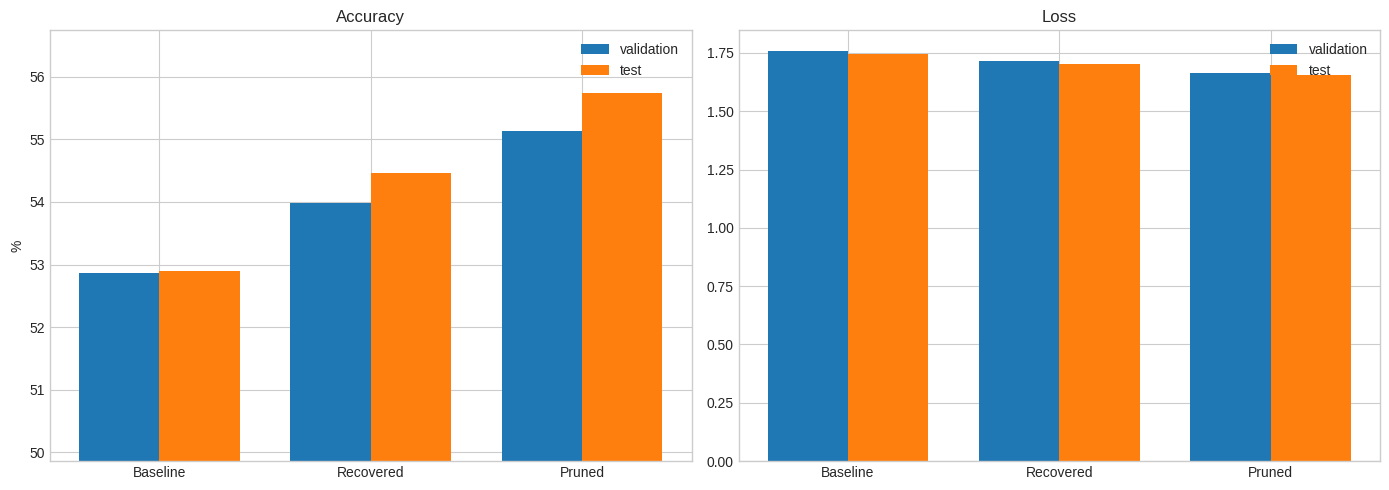

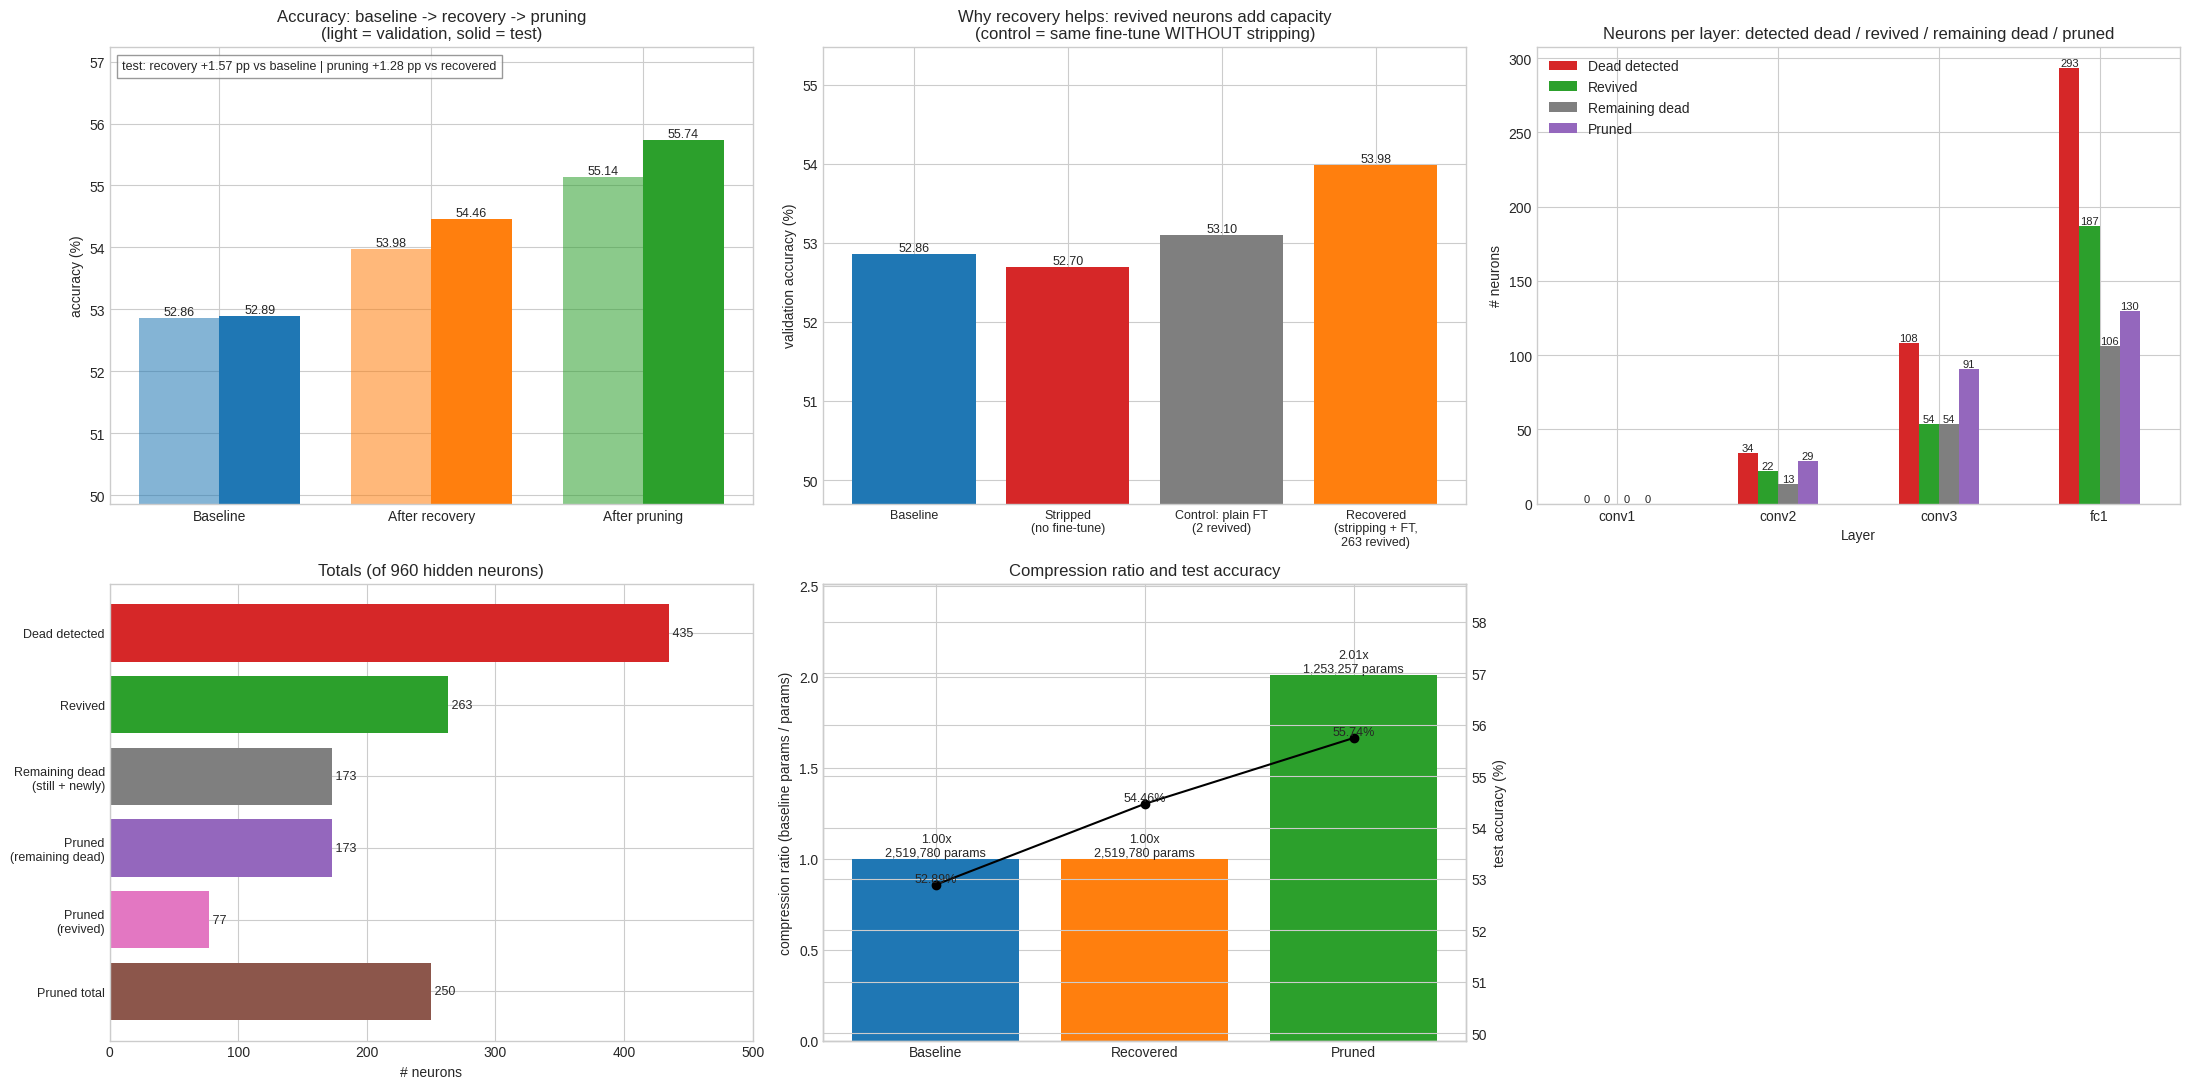

In [ ]:
# ===================== CELL 16 : GRAPHS =====================
# ------------------------------ Figure 1 : original panels (updated) ------------------------------
fig, ax = plt.subplots(2, 4, figsize=(24, 10))
# (a,b) baseline curves
ax[0, 0].plot(baseline_hist.epoch, baseline_hist.train_acc, label="train (aug)"); ax[0, 0].plot(baseline_hist.epoch, baseline_hist.val_acc, label="validation")
ax[0, 0].set(title="Baseline accuracy", xlabel="epoch", ylabel="%"); ax[0, 0].legend()
ax[0, 1].plot(baseline_hist.epoch, baseline_hist.train_loss, label="train"); ax[0, 1].plot(baseline_hist.epoch, baseline_hist.val_loss, label="validation")
ax[0, 1].set(title="Baseline loss", xlabel="epoch"); ax[0, 1].legend()
# (c) fine-tune curves
for h, nm in [(rec_hist, "recovery fine-tune"), (prune_hist, "final pruned fine-tune")]:
    if len(h): ax[0, 2].plot(h.epoch, h.val_acc, marker="o", label=nm)
ax[0, 2].axhline(base_val_acc, ls="--", c="gray", label="baseline val"); ax[0, 2].set(title="Fine-tuning (validation acc)", xlabel="epoch", ylabel="%"); ax[0, 2].legend()
# (d) per-layer counts (dead / revived / still dead / pruned)
cnt = pd.DataFrame({"dead": [len(dead_by_layer[l]) for l in HIDDEN_LAYERS],
                    "revived": [count_in(revived, l) for l in HIDDEN_LAYERS],
                    "still dead": [count_in(still_dead, l) for l in HIDDEN_LAYERS],
                    "pruned": [count_in(prune_ids, l) for l in HIDDEN_LAYERS]}, index=HIDDEN_LAYERS)
cnt.plot.bar(ax=ax[1, 0], rot=0); ax[1, 0].set(title="Dead / revived / still dead / pruned neurons per layer", ylabel="count")
# (e) importance histogram (revived neurons: kept by default; only those at/below 0 are pruning candidates)
if len(imp_df):
    ax[1, 1].hist(imp_df.acc_drop_pp, bins=min(30, max(5, len(imp_df))), color="tab:purple")
    ax[1, 1].axvline(pcfg.revived_tol_pp, c="r", ls="--", label=f"pruning candidate only if drop <= {pcfg.revived_tol_pp} pp (+ folds + loss)"); ax[1, 1].legend(fontsize=8)
    ax[1, 1].set(title="Individual ablation of revived neurons", xlabel="validation acc drop (pp)", ylabel="# neurons")
else:
    ax[1, 1].text(0.5, 0.5, "no revived neurons", ha="center", va="center"); ax[1, 1].set_axis_off()
# (f) accuracy comparison
x = np.arange(3); w = 0.38
ax[1, 2].bar(x - w/2, summary.Val_Acc, w, label="validation"); ax[1, 2].bar(x + w/2, summary.Test_Acc, w, label="test")
ax[1, 2].set_xticks(x); ax[1, 2].set_xticklabels(summary.Model); ax[1, 2].set(title="Accuracy", ylabel="%"); ax[1, 2].legend()
lo = min(summary.Val_Acc.min(), summary.Test_Acc.min()); ax[1, 2].set_ylim(max(0, lo - 3), max(summary.Val_Acc.max(), summary.Test_Acc.max()) + 1)
# (g) loss, (h) params
ax[0, 3].bar(x - w/2, summary.Val_Loss, w, label="validation"); ax[0, 3].bar(x + w/2, summary.Test_Loss, w, label="test")
ax[0, 3].set_xticks(x); ax[0, 3].set_xticklabels(summary.Model); ax[0, 3].set(title="Loss"); ax[0, 3].legend()
ax[1, 3].bar(summary.Model, summary.Params, color=["tab:blue", "tab:orange", "tab:green"]); ax[1, 3].set(title="Parameters (structural)")
for i, v in enumerate(summary.Params): ax[1, 3].text(i, v, f"{v:,}\n({summary.Compression_x[i]:.2f}x)", ha="center", va="bottom", fontsize=9)
ax[1, 3].set_ylim(0, summary.Params.max() * 1.18)
plt.tight_layout(); plt.savefig(os.path.join(cfg.ckpt_dir, "results.png"), dpi=130); plt.show()

# ------------------------------ Figure 2 : pipeline view ------------------------------
fig2, bx = plt.subplots(2, 3, figsize=(22, 11))
names = list(summary.Model); xs = np.arange(3); wd = 0.38
cols = ["tab:blue", "tab:orange", "tab:green"]

# (1) accuracy: baseline -> after recovery -> after pruning (validation + test)
b1 = bx[0, 0].bar(xs - wd/2, summary.Val_Acc, wd, label="validation", color=cols, alpha=0.55)
b2 = bx[0, 0].bar(xs + wd/2, summary.Test_Acc, wd, label="test", color=cols)
for bars in (b1, b2):
    for r_ in bars: bx[0, 0].text(r_.get_x() + r_.get_width()/2, r_.get_height(), f"{r_.get_height():.2f}", ha="center", va="bottom", fontsize=9)
bx[0, 0].set_xticks(xs); bx[0, 0].set_xticklabels(["Baseline", "After recovery", "After pruning"])
lo = min(summary.Val_Acc.min(), summary.Test_Acc.min()); hi = max(summary.Val_Acc.max(), summary.Test_Acc.max())
bx[0, 0].set_ylim(max(0, lo - 3), hi + 1.5); bx[0, 0].set(ylabel="accuracy (%)", title="Accuracy: baseline -> recovery -> pruning\n(light = validation, solid = test)")
bx[0, 0].text(0.02, 0.97, f"test: recovery {results['test']['recovered']['acc'] - results['test']['baseline']['acc']:+.2f} pp vs baseline | "
              f"pruning {results['test']['pruned']['acc'] - results['test']['recovered']['acc']:+.2f} pp vs recovered",
              transform=bx[0, 0].transAxes, va="top", fontsize=9, bbox=dict(fc="white", ec="gray", alpha=0.8))

# (2) WHY recovery improves accuracy: stripping vs plain fine-tuning (control)
why_names, why_vals, why_cols = ["Baseline"], [base_val_acc], ["tab:blue"]
if globals().get("sa") is not None and len(dead_initial) > 0: why_names.append("Stripped\n(no fine-tune)"); why_vals.append(sa); why_cols.append("tab:red")
if results["recovered"].get("control"):
    ci = results["recovered"]["control"]; why_names.append(f"Control: plain FT\n({ci['spontaneously_revived']} revived)"); why_vals.append(ci["val_acc"]); why_cols.append("tab:gray")
why_names.append(f"Recovered\n(stripping + FT,\n{len(revived)} revived)"); why_vals.append(rec_val_acc); why_cols.append("tab:orange")
bb = bx[0, 1].bar(range(len(why_vals)), why_vals, color=why_cols)
for i_, v_ in enumerate(why_vals): bx[0, 1].text(i_, v_, f"{v_:.2f}", ha="center", va="bottom", fontsize=9)
bx[0, 1].set_xticks(range(len(why_vals))); bx[0, 1].set_xticklabels(why_names, fontsize=9)
bx[0, 1].set_ylim(max(0, min(why_vals) - 3), max(why_vals) + 1.5)
bx[0, 1].set(ylabel="validation accuracy (%)", title="Why recovery helps: revived neurons add capacity\n(control = same fine-tune WITHOUT stripping)")

# (3) gradual pruning: accuracy vs compression
sx = stage_df.stage.values
bx[0, 2].plot(sx, stage_df.val_acc, "o-", c="tab:green", label="val acc after stage")
bx[0, 2].plot(sx, stage_df.val_acc_after_prune, "x--", c="tab:olive", label="val acc right after pruning (before ft)")
bx[0, 2].axhline(rec_val_acc, c="tab:orange", ls="--", label=f"recovered ({rec_val_acc:.2f}%)")
bx[0, 2].axhline(base_val_acc, c="tab:blue", ls=":", label=f"baseline ({base_val_acc:.2f}%)")
bx[0, 2].axhline(rec_val_acc - cfg.prune_tol_pp, c="r", ls=":", label="safety floor")
bx[0, 2].axhline(pv_acc, c="tab:green", ls="-.", alpha=0.5, label=f"after final fine-tune ({pv_acc:.2f}%)")
bx[0, 2].set(xlabel="pruning stage (0 = recovered model)", ylabel="validation accuracy (%)", title="Gradual pruning: accuracy vs compression")
bx[0, 2].legend(fontsize=8, loc="lower left"); bx[0, 2].set_xticks(sx)
tw = bx[0, 2].twinx(); tw.plot(sx, B["params"] / stage_df.params, "s-", c="tab:purple", label="compression ratio"); tw.set_ylabel("compression ratio (x params)", color="tab:purple")
tw.tick_params(axis="y", labelcolor="tab:purple")

# (4) per-layer neuron counts
lay = pd.DataFrame({"Dead detected": layer_df["Initially Dead"].values, "Revived": layer_df["Revived"].values,
                    "Remaining dead": (layer_df["Still Dead"] + layer_df["Newly Dead"]).values, "Pruned": layer_df["Pruned"].values}, index=layer_df.Layer)
lay.plot.bar(ax=bx[1, 0], rot=0, color=["tab:red", "tab:green", "tab:gray", "tab:purple"])
for c_ in bx[1, 0].containers: bx[1, 0].bar_label(c_, fontsize=8)
bx[1, 0].set(title="Neurons per layer: detected dead / revived / remaining dead / pruned", ylabel="# neurons")

# (5) totals funnel
tv = [len(dead_initial), len(revived), len(dead_now), n_pr_dead, n_pr_rev, len(prune_ids)]
tl_ = ["Dead detected", "Revived", "Remaining dead\n(still + newly)", "Pruned\n(remaining dead)", "Pruned\n(revived)", "Pruned total"]
bh = bx[1, 1].barh(range(len(tv))[::-1], tv, color=["tab:red", "tab:green", "tab:gray", "tab:purple", "tab:pink", "tab:brown"])
for i_, v_ in enumerate(tv): bx[1, 1].text(v_, len(tv) - 1 - i_, f" {v_}", va="center", fontsize=9)
bx[1, 1].set_yticks(range(len(tv))[::-1]); bx[1, 1].set_yticklabels(tl_, fontsize=9); bx[1, 1].set_xlim(0, max(tv + [1]) * 1.15)
bx[1, 1].set(title=f"Totals (of {sum(baseline.widths)} hidden neurons)", xlabel="# neurons")

# (6) compression ratio vs accuracy per model
bc = bx[1, 2].bar(names, summary.Compression_x, color=cols)
for i_, v_ in enumerate(summary.Compression_x): bx[1, 2].text(i_, v_, f"{v_:.2f}x\n{summary.Params[i_]:,} params", ha="center", va="bottom", fontsize=9)
bx[1, 2].set_ylim(0, max(summary.Compression_x) * 1.25); bx[1, 2].set(ylabel="compression ratio (baseline params / params)", title="Compression ratio and test accuracy")
t2 = bx[1, 2].twinx(); t2.plot(names, summary.Test_Acc, "ko-", label="test acc"); t2.set_ylabel("test accuracy (%)")
for i_, v_ in enumerate(summary.Test_Acc): t2.text(i_, v_, f"{v_:.2f}%", ha="center", va="bottom", fontsize=9)
t2.set_ylim(max(0, lo - 3), hi + 3)
plt.tight_layout(); plt.savefig(os.path.join(cfg.ckpt_dir, "results_pipeline.png"), dpi=130); plt.show()


In [ ]:
# ===================== CELL 17 : FINAL PRINTED SUMMARY (all values computed above) =====================
T = results["test"]
print("=" * 78)
print("FINAL SUMMARY" + ("   [SYNTHETIC SMOKE TEST - numbers are meaningless]" if cfg.synthetic_smoke_test else ""))
print("=" * 78)
print(f"Calibration set        : {X_calib.shape[0]} train images (fixed) | dead = post-ReLU exactly 0 over all samples and positions")
print(f"Initially dead         : {len(dead_initial)} / {sum(baseline.widths)} neurons  ->  per layer {dict(zip(HIDDEN_LAYERS, [len(dead_by_layer[l]) for l in HIDDEN_LAYERS]))}")
print(f"Revived (post fine-tune): {len(revived)}  | by method {results['recovered']['revived_by_method']}")
print(f"  revived right after stripping (pre fine-tune): {len(revived_pre_ft)} | still dead: {len(still_dead)} | newly dead: {len(newly_dead)}")
if results['recovered']['control']: print(f"  control (plain fine-tune, no stripping) revived: {results['recovered']['control']['spontaneously_revived']}")
print(f"Remaining dead tested  : {len(dead_now)} -> pruned {n_pr_dead} (no degradation when disabled) | kept {len(dead_now) - n_pr_dead} (disabling hurt / joint test / safety rollback)")
print(f"Revived neurons        : {len(revived)} -> kept {len(revived) - n_pr_rev} (default) | pruned {n_pr_rev} (repeatedly proven useless)")
print(f"Pruned (structural)    : {len(prune_ids)} neurons in {len(stage_df) - 1} gradual stage(s) | final fine-tune {'accepted' if final_ft_accepted else ('discarded' if final_ft_accepted is False else 'n/a')}")
print(f"Widths                 : {baseline.widths} -> {pruned_model.widths}")
print(f"Parameters             : {B['params']:,} -> {P['params']:,}  ({red(P['params']):.3f}% reduction, {cr(P['params']):.3f}x compression)")
print("-" * 78)
for n, d in [("Baseline", B), ("Recovered", R), ("Pruned", P)]:
    k = n.lower()
    print(f"{n:<10} val acc {d['val_acc']:6.2f}% loss {d['val_loss']:.4f} | TEST acc {T[k]['acc']:6.2f}% loss {T[k]['loss']:.4f}")
print(f"Test acc change: recovered vs baseline {T['recovered']['acc'] - T['baseline']['acc']:+.2f} pp | pruned vs baseline {T['pruned']['acc'] - T['baseline']['acc']:+.2f} pp "
      f"| pruned vs recovered {T['pruned']['acc'] - T['recovered']['acc']:+.2f} pp")
print("=" * 78)
print(layer_tab.to_string(index=False))
print("=" * 78)
with open(os.path.join(cfg.ckpt_dir, "final_results.json"), "w") as f:
    json.dump(dict(config=vars(cfg), prune_config=vars(pcfg), results=results, dead_initial=sorted(map(list, dead_initial)), revived=sorted(map(list, revived)),
                   pruned=sorted(map(list, prune_ids)), still_dead=sorted(map(list, still_dead)), newly_dead=sorted(map(list, newly_dead)),
                   decisions={f"{l}:{i}": d for (l, i), d in sorted(decisions.items())}, stages=stage_df.to_dict(orient="records"),
                   layerwise=layer_tab.to_dict(orient="records")),
              f, indent=2, default=str)
print("Saved: summary.csv, layerwise.csv, results.png, results_pipeline.png, final_results.json, dead_initial.json and checkpoints in", cfg.ckpt_dir)


FINAL SUMMARY
Calibration set        : 5000 train images (fixed) | dead = post-ReLU exactly 0 over all samples and positions
Initially dead         : 435 / 960 neurons  ->  per layer {'conv1': 0, 'conv2': 34, 'conv3': 108, 'fc1': 293}
Revived (post fine-tune): 263  | by method {'stripping': 263}
  revived right after stripping (pre fine-tune): 435 | still dead: 172 | newly dead: 1
  control (plain fine-tune, no stripping) revived: 2
Remaining dead tested  : 173 -> pruned 173 (no degradation when disabled) | kept 0 (disabling hurt / joint test / safety rollback)
Revived neurons        : 263 -> kept 186 (default) | pruned 77 (repeatedly proven useless)
Pruned (structural)    : 250 neurons in 9 gradual stage(s) | final fine-tune accepted
Widths                 : (64, 128, 256, 512) -> (64, 99, 165, 382)
Parameters             : 2,519,780 -> 1,253,257  (50.263% reduction, 2.011x compression)
------------------------------------------------------------------------------
Baseline   val acc  

## Limitations
* **Single seed, single run.** Differences of a few tenths of a percentage point are within seed-to-seed noise (the 5 000-image validation set also has a ≈ ±0.6 pp standard error; 0.1 pp equals ~5 images). Repeat with several seeds before drawing conclusions.
* **"Dead" is defined on a finite calibration set.** A neuron that is exactly zero on 5 000 images could fire on rarer inputs (Cell 6 also reports how many are dead on validation). Neurons count as *revived* if they fire on at least one calibration input – possibly very sparsely – so "revived" does not imply "useful" (that is what the ablation tests measure).
* **Remaining-dead neurons are pruned only if disabling them shows no degradation on the validation set.** Because they output exactly 0 on the calibration set, this is normally a free removal; the check still protects against neurons that fire on validation images.
* **Revived neurons are kept by default.** They are pruned only if they pass the strict repeated test (no drop overall and in each of 5 validation folds, no loss increase on validation or calibration). This is intentionally conservative, so compression comes mainly from removing dead neurons.
* **Pruning decisions, stage acceptance, rollback and the "accept final fine-tune" choice all use the validation set**, so the validation accuracy of the pruned model is slightly optimistic; the held-out test set is the unbiased number and is used only once, in Cell 14.
* **A plain ReLU CNN without BatchNorm may have few or even zero strictly dead neurons.** The notebook handles this (no-op pipeline) and never invents counts.
* **Synaptic Stripping here is a simplified implementation** (strip the most inhibitory incoming weights, using mean-input contributions) with a calibration-set criterion; it is not a line-by-line reproduction of the published method. The **fallback re-initialisation is not stripping** and is reported separately.
* **Importance by zero-ablation** ignores interactions beyond the joint check of each batch; fine-tuning may change accuracy in ways unrelated to the pruned neurons.
* GPU max-pool backward is non-deterministic, so exact bit-wise reproducibility across runs is not guaranteed.
* Weights stripped to zero are counted in the structural parameter count; `NonZeroParams` shows the count excluding them.
